# Copper–Zinc Spread, Gold and US Equities: Mean Reversion, Macro Sensitivity and Predictability (1973–today)

## Research question
Copper and zinc are both industrial metals driven by global manufacturing demand, but copper is more tied to electrification/construction and zinc to galvanised steel. We want to know if their price spread is a stable, mean-reverting object, and if it is driven by safe-haven (gold) and risk-appetite (US equities) shocks? Do these findings hold across eras and for other metal pairs?

## Hypotheses
|  | Hypothesis | Test |
|---|---|---|
| **H1** | The log Cu/Zn ratio is mean-reverting (cointegrated), but its half-life and stability vary across eras. | ADF, KPSS, Engle–Granger, Johansen, rolling half-life, era split |
| **H2** | Spread changes load **positively on US equity returns** (risk-on favours copper over zinc) and **negatively / insignificantly on gold** (risk-off). | HAC regressions at 1/3/12-month horizons, rolling betas, lead/lag placebo |
| **H3** | That sensitivity is **regime-dependent** (stronger when equity volatility is high). | Interaction regression on an ex-ante vol regime, 2-state Markov-switching regression |
| **H4** | Gold and equity information adds **out-of-sample** predictive power for future spread changes beyond plain mean reversion. | Expanding-window walk-forward, OOS R², Clark–West tests, IC, cost-aware illustrative backtest with bootstrap CI |
| **H5** | Cu/Zn is not special: other LME metal pairs show similar (or very different) mean reversion and macro loadings. | Same tests on Cu/Al, Cu/Ni, Zn/Pb, Al/Zn, Ni/Zn |

## Data sources
| Data | Source | Notes |
|---|---|---|
| Copper, zinc, aluminium, lead, nickel, gold, crude oil — monthly **average** prices, nominal USD | **World Bank Commodity Markets "Pink Sheet"** (`CMO-Historical-Data-Monthly.xlsx`), <https://www.worldbank.org/en/research/commodity-markets> | teacher-suggested source; metals are LME prices, gold is LBMA/market price |
| S&P 500 (monthly average of daily closes) | Yahoo Finance `^GSPC` via `yfinance` (primary); fallback: Robert Shiller's monthly S&P series mirrored in the `datasets/s-and-p-500` GitHub repo | averaged to match the Pink Sheet's monthly-average convention |
| Cross-check: IMF copper & zinc | **FRED** series `PCOPPUSDM`, `PZINCUSDM` (IMF Primary Commodity Prices), <https://fred.stlouisfed.org> | teacher-suggested sources (IMF, FRED) |

Downloaded files are cached in `./data/` — **submit that folder together with the notebook** so the grader can rerun it even if a website changes (World Bank file URLs change every year; the notebook scrapes the current link and has fallbacks).

## References (explicitly reused ideas)
* Walk-forward / purged out-of-sample evaluation and Spearman-IC evaluation follow the style of the public solutions to the Kaggle *MITSUI&CO. Commodity Prediction Challenge* (<https://www.kaggle.com/competitions/mitsui-commodity-prediction-challenge>); that competition's data is not used here because it is no longer downloadable.
* Engle & Granger (1987), *Co-integration and error correction*, Econometrica. Johansen (1991), Econometrica.
* Newey & West (1987) HAC standard errors (via `statsmodels`).
* Campbell & Thompson (2008), *Predicting excess stock returns out of sample*, RFS (OOS R² vs historical mean).
* Clark & West (2007), *Approximately normal tests for equal predictive accuracy in nested models*, J. Econometrics.
* Hamilton (1989), Econometrica (Markov-switching regression, `statsmodels.tsa.MarkovRegression`).
* Politis & Romano (1994), stationary bootstrap (re-implemented below).
* Working (1960), *Note on the correlation of first differences of averages in a random chain*, Econometrica — why returns built from monthly **averages** are autocorrelated (relevant for §3).

All code below is my own, written for this project.

**Requirements:** `numpy pandas scipy statsmodels scikit-learn matplotlib openpyxl requests` (+ optional `yfinance`; `pip install yfinance` if missing). Runtime: about 1–3 minutes.

# Copper–Zinc Spread, Gold and US Equities: Mean Reversion, Macro Sensitivity and Predictability

## Research question
Copper and zinc are both industrial metals driven by global manufacturing demand, but copper is more tied to electrification/construction and zinc to galvanised steel. Is their price spread a stable, mean-reverting object, and is it driven by safe-haven (gold) and risk-appetite (US equities) shocks? Do these findings hold across eras and for other metal pairs?

## Hypotheses
| # | Hypothesis | Test |
|---|---|---|
| **H1** | The log Cu/Zn ratio is mean-reverting (cointegrated), but its half-life and stability vary across eras. | ADF, KPSS, Engle–Granger, Johansen, rolling half-life, era split |
| **H2** | Spread changes load **positively on US equity returns** (risk-on favours copper over zinc) and **negatively / insignificantly on gold** (risk-off). | HAC regressions at 1/3/12-month horizons, rolling betas, lead/lag placebo |
| **H3** | That sensitivity is **regime-dependent** (stronger when equity volatility is high). | Interaction regression on an ex-ante vol regime, 2-state Markov-switching regression |
| **H4** | Gold and equity information adds **out-of-sample** predictive power for future spread changes beyond plain mean reversion. | Expanding-window walk-forward, OOS R², Clark–West tests, IC, cost-aware illustrative backtest with bootstrap CI |
| **H5** | Cu/Zn is not special: other LME metal pairs show similar (or very different) mean reversion and macro loadings. | Same tests on Cu/Al, Cu/Ni, Zn/Pb, Al/Zn, Ni/Zn |

In [1]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [2]:
## Preparation

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.regression.rolling import RollingOLS
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

SEED = 1
rng = np.random.default_rng(SEED)

CFG = dict(roll_window=180, horizons=[1, 3, 12])

## 1. Data

1. World Bank Pink Sheet: monthly average prices.
2. Git: monthly average of S&P 500 index.

In [3]:
# World Bank Pink Sheet
cmo = pd.read_excel(
    "CMO_monthly.xlsx",
    sheet_name="Monthly Prices",
    header=4
)

cmo.rename(columns={cmo.columns[0]: "Date"}, inplace=True)
cmo["Date"] = pd.to_datetime(cmo["Date"], format="%YM%m")
cmo = cmo[['Date', 'Zinc', 'Copper', 'Gold', 'Aluminum', 'Lead', 'Nickel', 'Crude oil, average']]
cmo

,Date,Zinc,Copper,Gold,Aluminum,Lead,Nickel,"Crude oil, average"
0,NaT,($/mt),($/mt),($/troy oz),($/mt),($/mt),($/mt),($/bbl)
1,1960-01-01,261,715,35,511,206,1631,1.6
2,1960-02-01,245,728,35,511,204,1631,1.6
3,1960-03-01,249,685,35,511,210,1631,1.6
4,1960-04-01,255,723,35,511,214,1631,1.6
...,...,...,...,...,...,...,...,...
798,2026-06-01,3539,13552,4228,3439,1946,17588,81.7
799,2026-07-01,3599,13543,4073,3161,1842,16651,79.8
800,2026-08-01,3875,14326,4411,3251,1855,16751,84.4
801,2026-09-01,4021,14474,4319,3283,1873,16324,102.3


In [4]:
# S&P 500
snp = pd.read_csv("https://raw.githubusercontent.com/datasets/s-and-p-500/main/data/data.csv",
    parse_dates=["Date"])
snp = snp[["Date", "SP500"]]
snp = snp[snp["Date"] >= "1960-01-01"]
snp

,Date,SP500
1068,1960-01-01,58.03
1069,1960-02-01,55.78
1070,1960-03-01,55.02
1071,1960-04-01,55.73
1072,1960-05-01,55.22
...,...,...
1864,2026-05-01,7412.55
1865,2026-06-01,7450.03
1866,2026-07-01,7481.34
1867,2026-08-01,7711.32


In [5]:
df = pd.merge(cmo, snp, on="Date", how="inner")
for col in df.columns:
    if col != 'Date':
        df[col] = pd.to_numeric(df[col], errors='coerce')
df['Spread ln(cu) - ln(zn)'] = np.log(df['Copper']) - np.log(df['Zinc']) 
df

,Date,Zinc,Copper,Gold,Aluminum,Lead,Nickel,"Crude oil, average",SP500,Spread ln(cu) - ln(zn)
0,1960-01-01,261,715,35,511,206,1631,1.6,58.03,1.007762
1,1960-02-01,245,728,35,511,204,1631,1.6,55.78,1.089043
2,1960-03-01,249,685,35,511,210,1631,1.6,55.02,1.011966
3,1960-04-01,255,723,35,511,214,1631,1.6,55.73,1.042146
4,1960-05-01,254,685,35,511,213,1631,1.6,55.22,0.992085
...,...,...,...,...,...,...,...,...,...,...
796,2026-05-01,3482,13543,4587,3666,1991,18806,100.4,7412.55,1.358263
797,2026-06-01,3539,13552,4228,3439,1946,17588,81.7,7450.03,1.342690
798,2026-07-01,3599,13543,4073,3161,1842,16651,79.8,7481.34,1.325214
799,2026-08-01,3875,14326,4411,3251,1855,16751,84.4,7711.32,1.307530


Text(0, 0.5, 'Correlation')

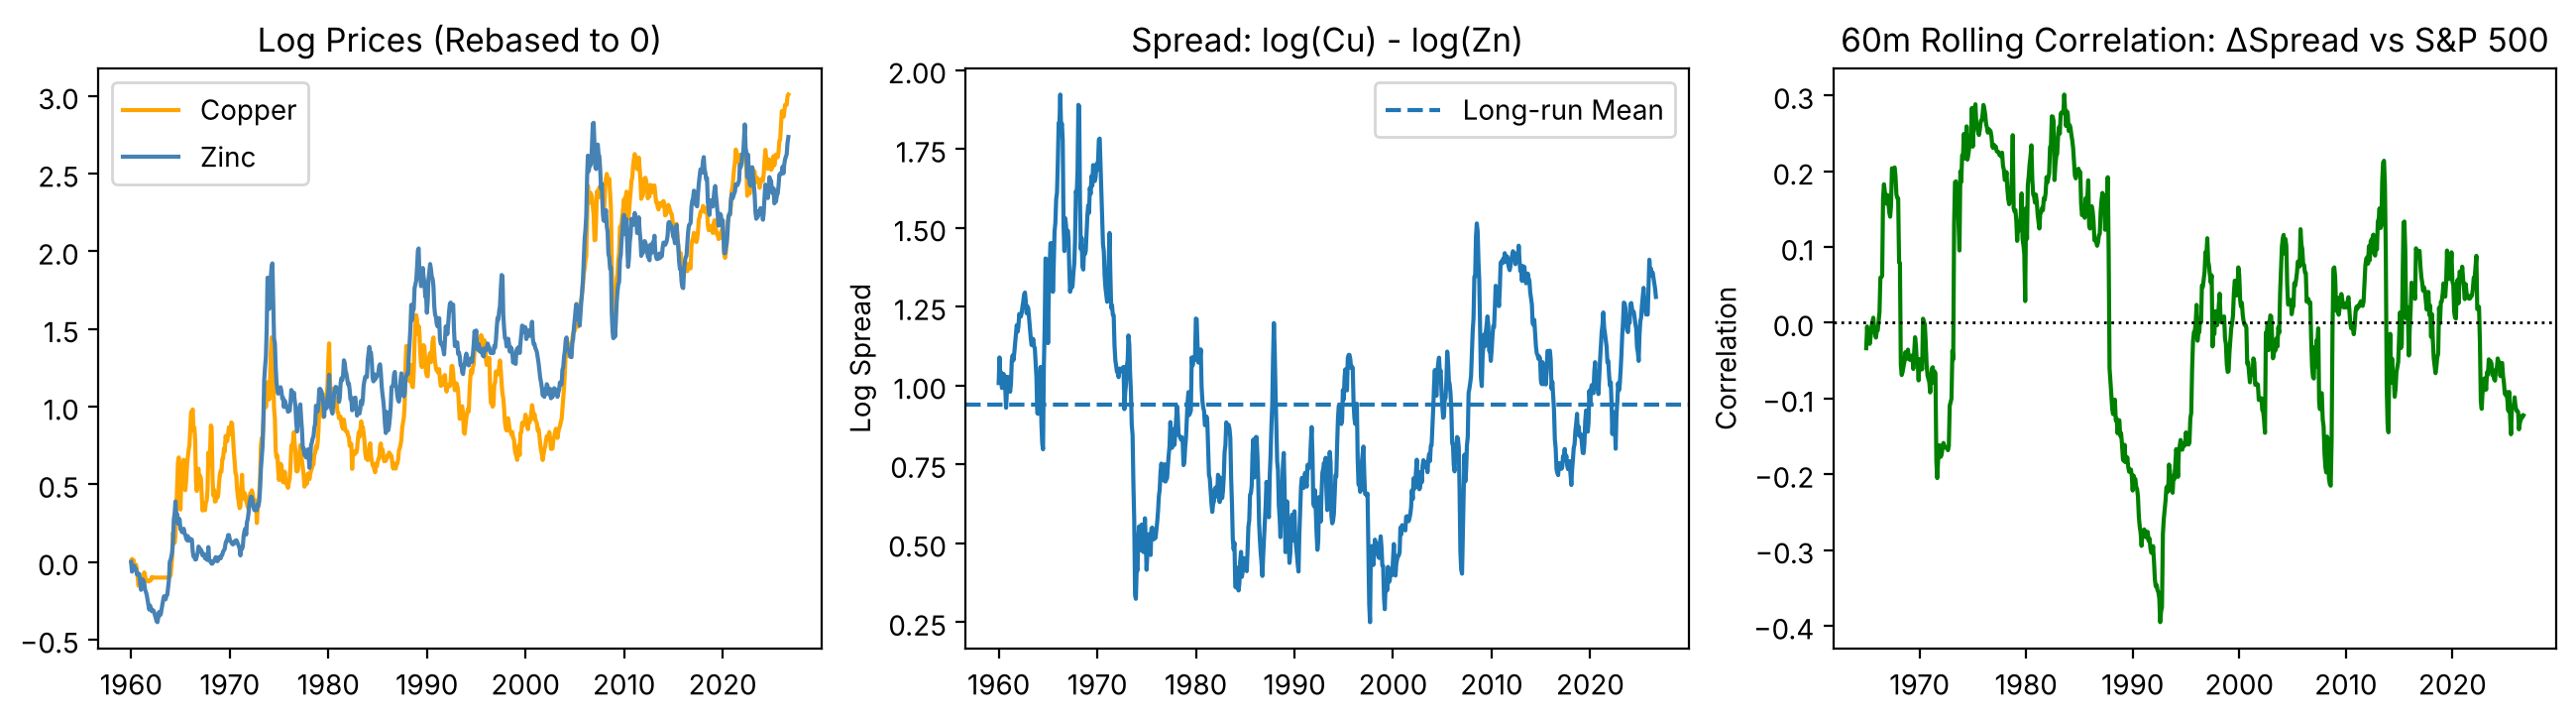

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))

ax[0].plot(df['Date'], np.log(df['Copper']) - np.log(df['Copper'].iloc[0]), label='Copper', color='orange')
ax[0].plot(df['Date'], np.log(df['Zinc']) - np.log(df['Zinc'].iloc[0]), label='Zinc', color='steelblue')
ax[0].set_title("Log Prices (Rebased to 0)")
ax[0].legend()

ax[1].plot(df['Date'], df['Spread ln(cu) - ln(zn)'])
ax[1].axhline(df['Spread ln(cu) - ln(zn)'].mean(), linestyle='--', label='Long-run Mean')
ax[1].set_title("Spread: log(Cu) - log(Zn)")
ax[1].set_ylabel("Log Spread")
ax[1].legend()

spread_ret = df['Spread ln(cu) - ln(zn)'].diff()
equity_ret = df['SP500'].pct_change()  # equivalent to log return for small changes
rolling_corr = spread_ret.rolling(60).corr(equity_ret)
ax[2].plot(df['Date'], rolling_corr, color='green')
ax[2].axhline(0, color='black', linestyle=':', linewidth=1) # zero line for reference
ax[2].set_title("60m Rolling Correlation: ΔSpread vs S&P 500")
ax[2].set_ylabel("Correlation")

In [7]:
NAMES = {"Copper": "cu", "Zinc": "zn", "Gold": "gold", "SP500": "eq",
         "Aluminum": "al", "Aluminium": "al", "Lead": "pb", "Nickel": "ni", "Oil": "oil"}
raw = df.rename(columns=NAMES).drop(columns=["Spread"], errors="ignore")
raw["Date"] = pd.to_datetime(raw["Date"])
raw = raw.set_index("Date").sort_index().apply(pd.to_numeric, errors="coerce")
raw = raw.dropna(subset=["cu", "zn", "gold", "eq"])
lev = np.log(raw)                                          # log levels (monthly averages)
rets = lev[["cu", "zn", "gold", "eq"]].diff().dropna()    # monthly log returns
s = lev["cu"] - lev["zn"]                                  # log Cu/Zn ratio = "spread"
rets["ds"] = rets["cu"] - rets["zn"]                       # spread change

## 2. H1 – Is the Cu/Zn spread mean-reverting?

If both metals share a common global-demand trend, `log Cu − β·log Zn` should be stationary. We combine ADF (H0: unit root), KPSS (H0: stationary — the opposite null, so agreement is stronger evidence), Engle–Granger and Johansen cointegration tests, and the AR(1) half-life with a residual-bootstrap CI. Because structural change is the main risk for any pairs idea, we also track a rolling ADF p-value / half-life and split the sample into eras.

In [8]:
def halflife(x):
    x = np.asarray(x, float); y, X = x[1:], sm.add_constant(x[:-1])
    b = np.linalg.lstsq(X, y, rcond=None)[0]; phi = b[1]
    return (-np.log(2) / np.log(phi)) if 0 < phi < 1 else np.inf, phi, b, y - X @ b

def boot_halflife(x, B=500):
    x = np.asarray(x, float); hl, phi, b, e = halflife(x); out = []
    for _ in range(B):
        ee = rng.choice(e, len(e)); xs = np.empty(len(e) + 1); xs[0] = x[0]
        for i in range(len(e)): xs[i + 1] = b[0] + b[1] * xs[i] + ee[i]
        out.append(halflife(xs)[0])
    return np.nanpercentile(np.minimum(out, 1e4), [5, 50, 95])

R = {}

adf = adfuller(s, regression="c", autolag="AIC"); kp = kpss(s, regression="c", nlags="auto")
eg = coint(lev["cu"], lev["zn"], trend="c", autolag="aic"); jo = coint_johansen(lev[["cu", "zn"]], det_order=0, k_ar_diff=2)
ols = sm.OLS(lev["cu"], sm.add_constant(lev["zn"])).fit(); hl, phi, *_ = halflife(s); ci = boot_halflife(s)
tab = pd.DataFrame({"statistic": [adf[0], kp[0], eg[0], jo.lr1[0]],
                    "p-value / crit.": [adf[1], kp[1], eg[1], f"5% crit={jo.cvt[0,1]:.2f}"],
                    "reading": ["p<0.05 ⇒ reject unit root", "p>0.05 ⇒ cannot reject stationarity", "p<0.05 ⇒ cointegrated", "trace>crit ⇒ rank ≥1"]},
                   index=["ADF (spread)", "KPSS (spread)", "Engle–Granger (Cu,Zn)", "Johansen trace (r=0)"])
display(tab.round(4))
print(f"Cointegrating slope (log Cu on log Zn): beta = {ols.params['zn']:.3f}  (β=1 ⇔ log-ratio spread)")
print(f"AR(1) phi = {phi:.4f}; half-life = {hl:.1f} months; bootstrap 5/50/95% = {np.round(ci, 1)} months")
R["H1"] = dict(adf_p=adf[1], kpss_p=kp[1], eg_p=eg[1], johansen_reject=bool(jo.lr1[0] > jo.cvt[0, 1]), beta=ols.params["zn"], halflife=hl, hl_ci=ci)

/tmp/ipykernel_137/2484533048.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(s, regression="c", autolag="AIC"); kp = kpss(s, regression="c", nlags="auto")
/tmp/ipykernel_137/2484533048.py:16: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(s, regression="c", autolag="AIC"); kp = kpss(s, regression="c

,statistic,p-value / crit.,reading
ADF (spread),-2.0666,0.258144,p<0.05 ⇒ reject unit root
KPSS (spread),0.5877,0.023751,p>0.05 ⇒ cannot reject stationarity
"Engle–Granger (Cu,Zn)",-1.8327,0.613721,p<0.05 ⇒ cointegrated
Johansen trace (r=0),10.5140,5% crit=15.49,trace>crit ⇒ rank ≥1


Cointegrating slope (log Cu on log Zn): beta = 0.904  (β=1 ⇔ log-ratio spread)
AR(1) phi = 0.9842; half-life = 43.5 months; bootstrap 5/50/95% = [18.2 34.4 64.9] months


/tmp/ipykernel_137/2776298925.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))
/tmp/ipykernel_137/2776298925.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))


/tmp/ipykernel_137/2776298925.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))
/tmp/ipykernel_137/2776298925.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))


/tmp/ipykernel_137/2776298925.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))
/tmp/ipykernel_137/2776298925.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))


/tmp/ipykernel_137/2776298925.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))
/tmp/ipykernel_137/2776298925.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))


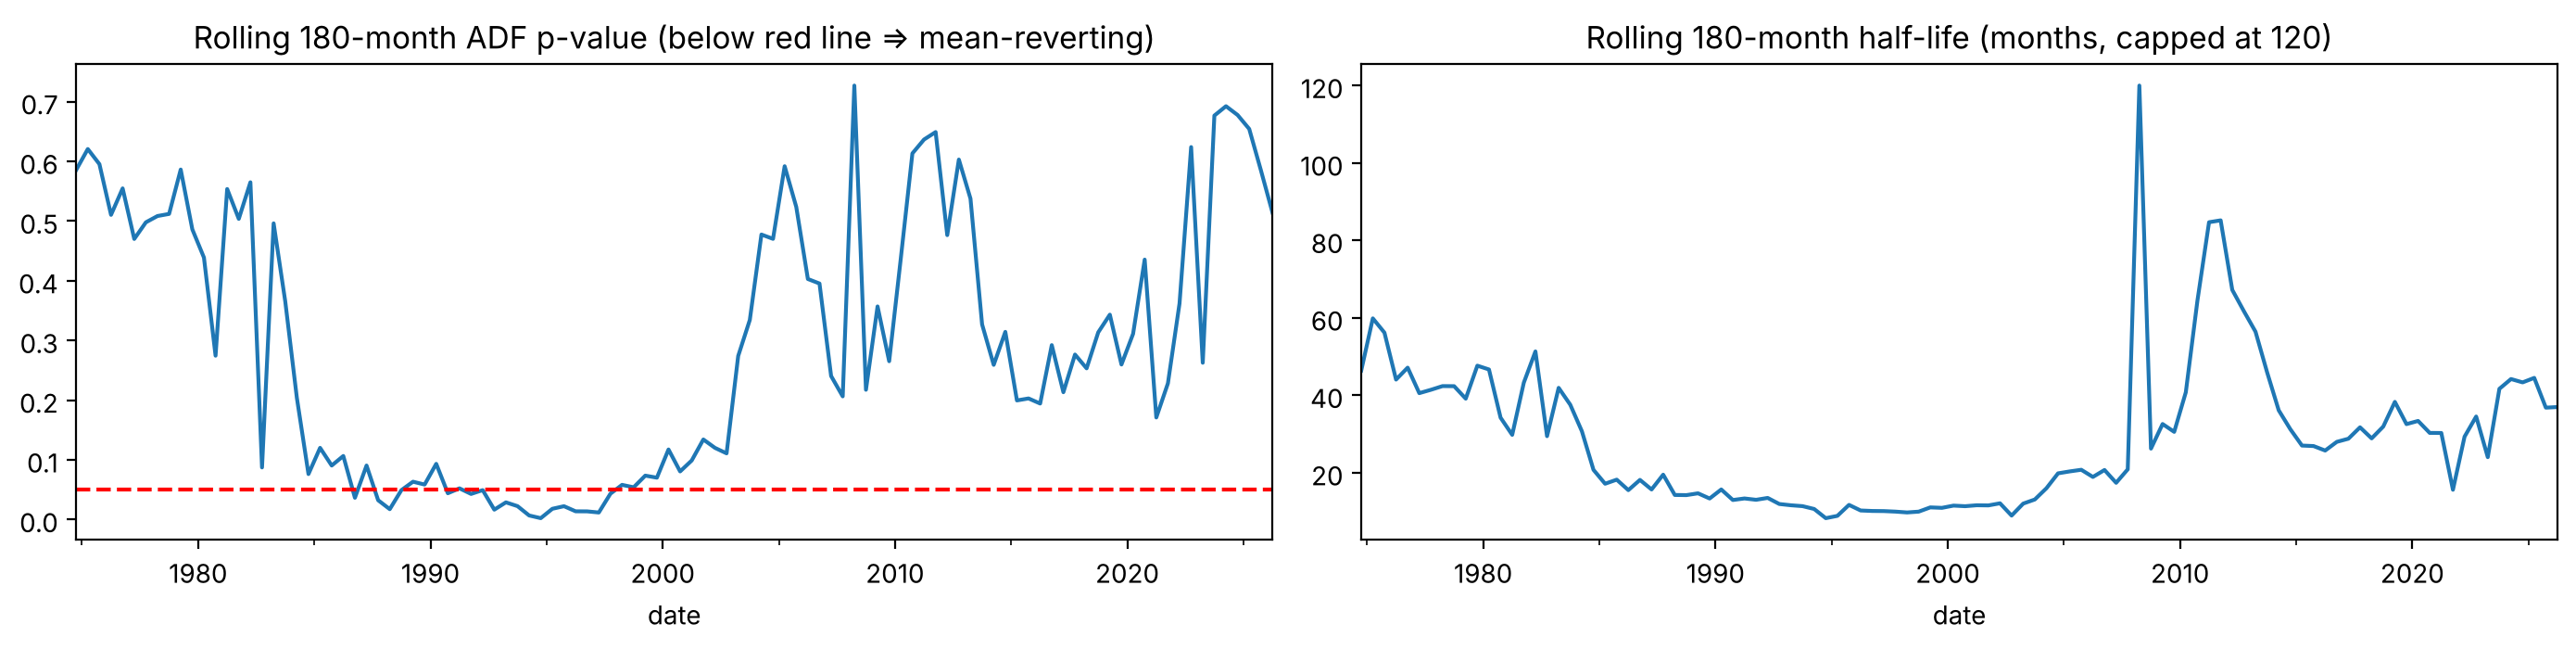

Share of rolling windows where a unit root is rejected at 5%: 17%


In [9]:
W, rows = 180, []
for end in range(W, len(s) + 1, 6):
    w = s.iloc[end - W:end]
    rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))
roll = pd.DataFrame(rows, columns=["date", "adf_p", "half_life"]).set_index("date")
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
roll["adf_p"].plot(ax=ax[0], title=f"Rolling {W}-month ADF p-value (below red line ⇒ mean-reverting)"); ax[0].axhline(.05, c="r", ls="--")
roll["half_life"].plot(ax=ax[1], title=f"Rolling {W}-month half-life (months, capped at 120)")
plt.tight_layout(); plt.show()
share = (roll["adf_p"] < .05).mean(); R["H1"]["share_stationary_windows"] = share
print(f"Share of rolling windows where a unit root is rejected at 5%: {share:.0%}")

/tmp/ipykernel_137/3045356086.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))
/tmp/ipykernel_137/3045356086.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))


/tmp/ipykernel_137/3045356086.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))
/tmp/ipykernel_137/3045356086.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))


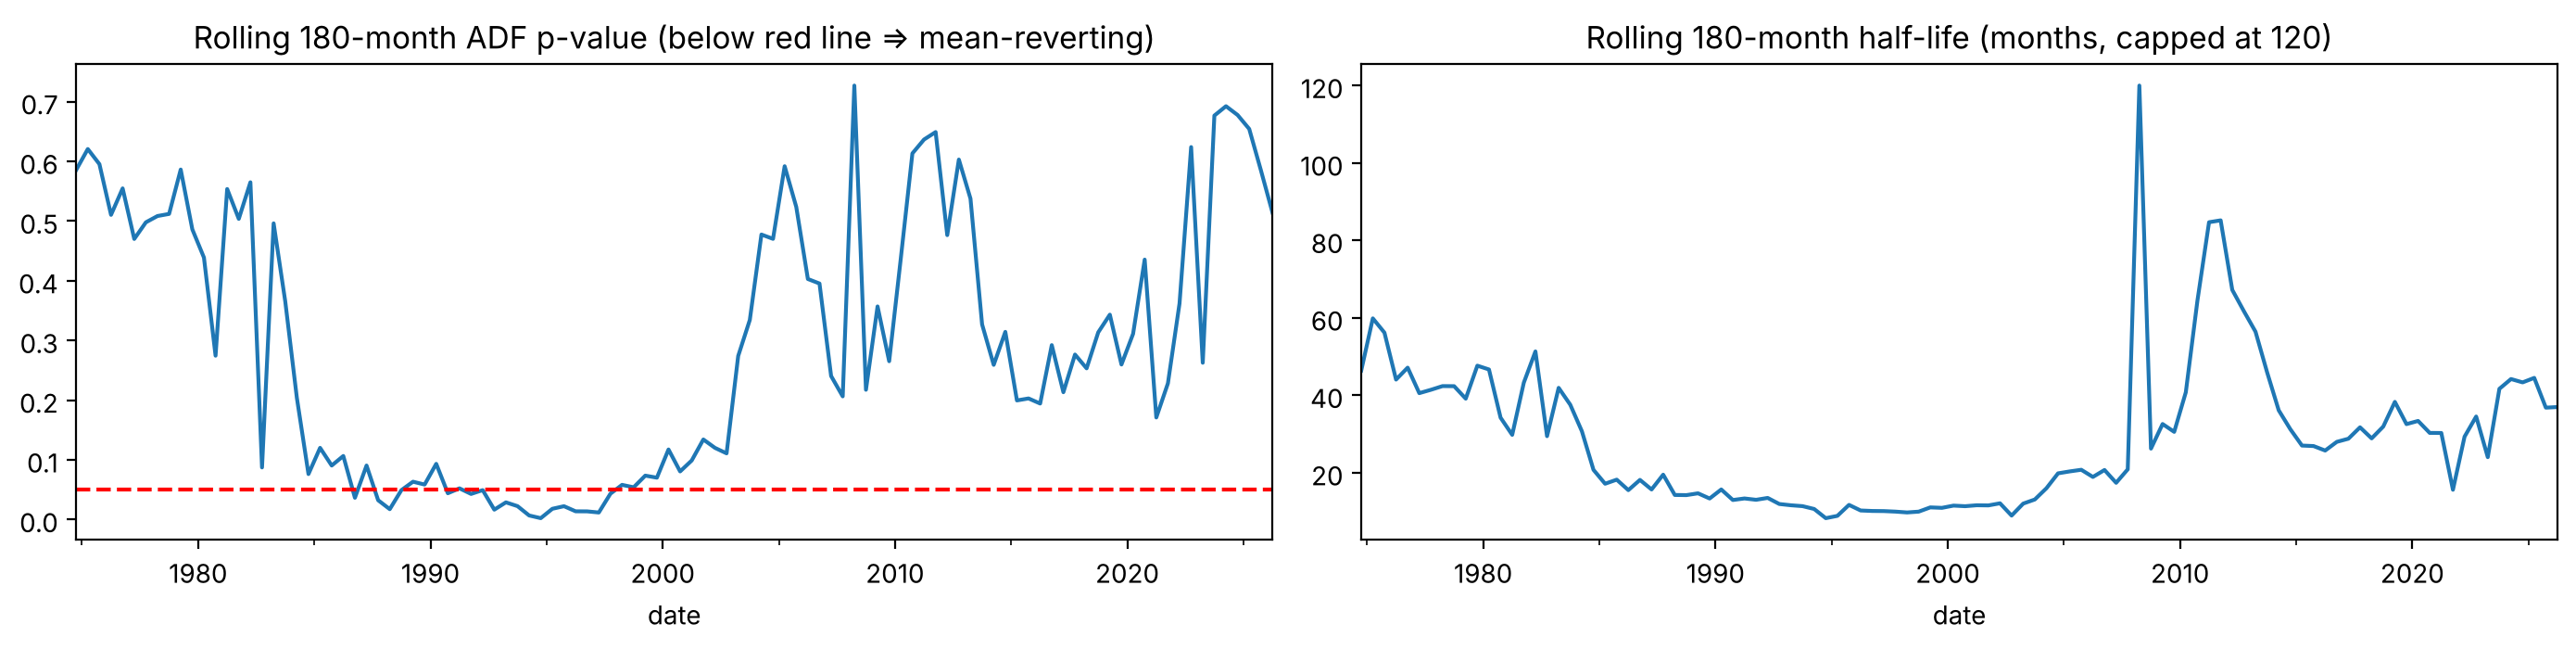

Share of rolling windows where a unit root is rejected at 5%: 17%


In [10]:
W, rows = CFG["roll_window"], []
for end in range(W, len(s) + 1, 6):
    w = s.iloc[end - W:end]
    rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))
roll = pd.DataFrame(rows, columns=["date", "adf_p", "half_life"]).set_index("date")
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
roll["adf_p"].plot(ax=ax[0], title=f"Rolling {W}-month ADF p-value (below red line ⇒ mean-reverting)"); ax[0].axhline(.05, c="r", ls="--")
roll["half_life"].plot(ax=ax[1], title=f"Rolling {W}-month half-life (months, capped at 120)")
plt.tight_layout(); plt.show()
share = (roll["adf_p"] < .05).mean(); R["H1"]["share_stationary_windows"] = share
print(f"Share of rolling windows where a unit root is rejected at 5%: {share:.0%}")

## 3. H2 – Do gold and US equities drive the spread?

HAC (Newey–West) regressions of spread changes on gold and equity returns; overlapping multi-month horizons need HAC. Three angles:

1. **Horizon regressions** (1, 3, 12 months): `Δs = a + b_eq·r_eq + b_gold·r_gold + e`.
2. **Which leg carries the sensitivity?** Same regression for copper and zinc separately — a positive spread beta means copper is *more* equity-sensitive than zinc.
3. **Lead/lag placebo test.** Regress `Δs_t` on equity returns at `t−1, t, t+1`. With monthly averages, a significant `t−1` coefficient reflects smoothing/delayed transmission (Working 1960) rather than a tradable lead; the **future** return (`t+1`) must be ≈0 — if it is not, something in the alignment is wrong.

In [11]:
def agg(x, h): return x.rolling(h).sum() if h > 1 else x
def hac(y, X, lags):
    return sm.OLS(y, sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": lags})

rows = []
for h in CFG["horizons"]:
    d = pd.concat({"y": agg(rets["ds"], h), "eq": agg(rets["eq"], h), "gold": agg(rets["gold"], h)}, axis=1).dropna()
    m = hac(d["y"], d[["eq", "gold"]], h + 3)
    rows.append(dict(h_months=h, n=int(m.nobs), b_eq=m.params["eq"], t_eq=m.tvalues["eq"], b_gold=m.params["gold"], t_gold=m.tvalues["gold"], R2=m.rsquared))
H2 = pd.DataFrame(rows).set_index("h_months"); display(H2.round(3)); R["H2"] = H2

leg = {}
for nm, y in [("Copper", rets["cu"]), ("Zinc", rets["zn"]), ("Cu−Zn spread", rets["ds"])]:
    d = pd.concat([y.rename("y"), rets[["eq", "gold"]]], axis=1).dropna(); m = hac(d["y"], d[["eq", "gold"]], 4)
    leg[nm] = dict(b_eq=m.params["eq"], t_eq=m.tvalues["eq"], b_gold=m.params["gold"], t_gold=m.tvalues["gold"], R2=m.rsquared)
display(pd.DataFrame(leg).T.round(3))

,n,b_eq,t_eq,b_gold,t_gold,R2
h_months,,,,,,
1,800,0.013,0.169,0.143,2.983,0.011
3,798,0.000,0.004,0.153,2.807,0.012
12,789,-0.030,-0.236,0.136,1.062,0.015


,b_eq,t_eq,b_gold,t_gold,R2
Copper,0.399,3.258,0.367,5.984,0.110
Zinc,0.386,4.401,0.223,3.231,0.078
Cu−Zn spread,0.013,0.169,0.143,2.983,0.011


Equity returns -> Δspread


,coef,t-stat,p
lag1,-0.0333,-0.4342,0.6641
t,0.0279,0.4018,0.6878
lead1,-0.0134,-0.2110,0.8329


Gold returns -> Δspread


,coef,t-stat,p
lag1,0.0619,1.5017,0.1332
t,0.1331,2.6044,0.0092
lead1,-0.0236,-0.4975,0.6189


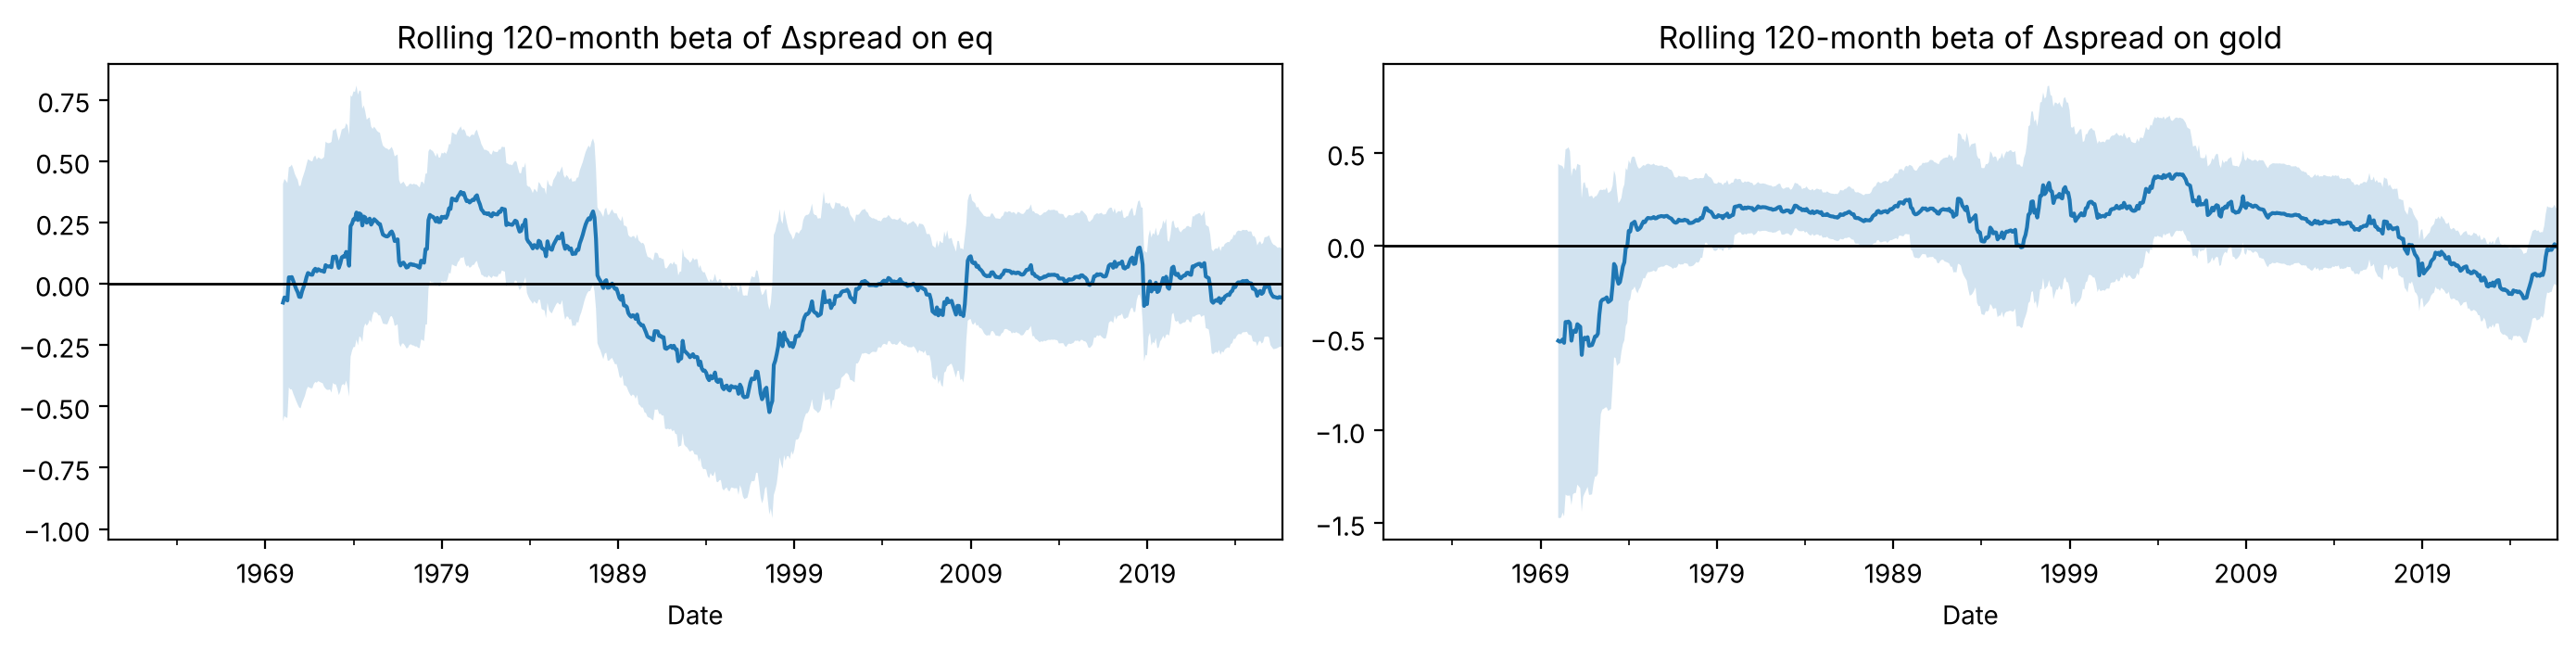

In [12]:
def timing_table(col):
    d = pd.concat({"y": rets["ds"], "lag1": rets[col].shift(1), "t": rets[col], "lead1": rets[col].shift(-1)}, axis=1).dropna()
    m = hac(d["y"], d[["lag1", "t", "lead1"]], 4)
    return pd.DataFrame({"coef": m.params, "t-stat": m.tvalues, "p": m.pvalues}).drop("const")
tt_eq, tt_gold = timing_table("eq"), timing_table("gold")
print("Equity returns -> Δspread"); display(tt_eq.round(4)); print("Gold returns -> Δspread"); display(tt_gold.round(4))
R["timing_eq"] = tt_eq

d = pd.concat([rets["ds"].rename("y"), rets[["eq", "gold"]]], axis=1).dropna()
rr = RollingOLS(d["y"], sm.add_constant(d[["eq", "gold"]]), window=120).fit()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
for a, c in zip(ax, ["eq", "gold"]):
    b, se = rr.params[c], rr.bse[c]
    b.plot(ax=a, title=f"Rolling 120-month beta of Δspread on {c}"); a.fill_between(b.index, b - 1.96 * se, b + 1.96 * se, alpha=.2); a.axhline(0, c="k", lw=1)
plt.tight_layout(); plt.show()

In [13]:
# ===== Added for H3–H5 =====
# Extra imports, helpers and configuration used from here on (the cells above are left unchanged)
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Sorting by default")
warnings.filterwarnings("ignore", message="No frequency information")
warnings.filterwarnings("ignore", message="The test statistic is outside")
warnings.filterwarnings("ignore", message="Casting complex values")

CFG = dict(
    roll_window=180,          # rolling window (months) for ADF / half-life
    horizons=[1, 3, 12],      # regression horizons
    start="1973-01-01",       # free-floating gold & post-Bretton-Woods sample (H3-H4)
    lme_start="1980-01-01",   # all six metals LME-priced (H5)
    vol_window=12,            # equity-vol window for the regime (H3)
    min_train=144,            # 12 years of first training sample (H4)
    refit=12,                 # re-estimate once a year (H4)
    target_vol=0.10,          # ex-ante annual vol target for the illustrative strategy
    costs_bps=[0, 5, 10, 25], # one-way cost per leg, in bps
)

def agg(x, h): return x.rolling(h).sum() if h > 1 else x
def hac(y, X, lags):
    return sm.OLS(y, sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
def halflife(x):
    x = np.asarray(x, float); y, X = x[1:], sm.add_constant(x[:-1])
    b = np.linalg.lstsq(X, y, rcond=None)[0]; phi = b[1]
    return (-np.log(2) / np.log(phi)) if 0 < phi < 1 else np.inf, phi, b, y - X @ b
R = globals().get("R", {})

### Note on the sample used from here on
Before testing H3–H5, a look at the raw Pink Sheet shows that several series are **administered prices** in the early years: gold is fixed at $35/oz until the end of Bretton Woods (≈1971), and aluminium and nickel are producer prices (many months with a 0 change) until the LME contracts start (aluminium 1978, nickel 1979). A regression on gold returns that are mostly zero, or a pair test on a constant price, says nothing about markets. Following the course's warning on *dirty data* (Ch. 16, "Dirty data and jumps"), we therefore use:

* **1973 → today** for the Cu/Zn tests of H3–H4 (free-floating gold and the "1973–today" scope of the title);
* **1980 → today** for the cross-pair comparison of H5 (all six metals are market prices).

In [14]:
zero_share = (np.log(raw[["cu", "zn", "gold", "al", "pb", "ni"]]).diff() == 0)
zs = pd.DataFrame({"1960-72": zero_share[:"1972"].mean(), "1973-79": zero_share["1973":"1979"].mean(),
                   "1980-today": zero_share["1980":].mean()})
display((zs * 100).round(1).rename_axis("% of months with a 0 price change"))

,1960-72,1973-79,1980-today
% of months with a 0 price change,,,
cu,13.5,1.2,0.4
zn,8.3,1.2,0.4
gold,73.7,3.6,4.1
al,84.0,7.1,1.2
pb,3.8,2.4,1.2
ni,82.7,73.8,0.2


## 4. H3 – Is the sensitivity regime-dependent?

> 🔑 **Key result: rejected.** The spread's equity beta is ≈ 0 in calm *and* in stressed markets (t of the interaction ≈ 0.3), in all 6 regime definitions. The spread has its own turbulent regimes, and they are not equity-volatility regimes.


H2 measures *average* loadings. H3 asks whether the equity (and gold) loading of the spread is **larger when equity volatility is high** — the risk-on / risk-off story in which industrial metals and stocks become a single "global growth" trade in stressed markets.

**Regime definition (ex-ante, no look-ahead).** At each month *t* we compute the realised volatility of S&P 500 log returns over the previous 12 months, lag it one month, and call the month *high-vol* if that value is above its **expanding** median (computed only with data up to *t−1*). This is the same discipline as in the course's backtests (Ch. 4: "at each date, only information up to that date is used").

Three tests:
1. **Interaction regression** (HAC): `Δs = a + b_eq·r_eq + b_gold·r_gold + c·High + d_eq·High·r_eq + d_gold·High·r_gold + e`. H3 ⇔ `d_eq > 0` (and the joint Wald test on `d_eq, d_gold`).
2. **Per-regime statistics**, including the course's non-normality diagnostics (skewness, excess kurtosis, Jarque–Bera, Ch. 11): if the spread is a mixture of a calm and a stressed regime, the full sample should be fat-tailed while each regime is closer to Gaussian.
3. **Hamilton (1989) Markov-switching regression** with 2 states, switching betas and switching variance — the regimes are *learned* from the spread itself, and we check whether they line up with the equity-vol regime.

In [15]:
S3 = CFG["start"]
vol_eq = rets["eq"].rolling(CFG["vol_window"]).std() * np.sqrt(12)   # annualised realised vol
vol_ex_ante = vol_eq.shift(1)                                        # known at the start of month t
thr = vol_ex_ante.expanding(60).median()                             # expanding median: no look-ahead
high = (vol_ex_ante > thr).astype(float).where(thr.notna())

d3 = pd.concat({"ds": rets["ds"], "eq": rets["eq"], "gold": rets["gold"], "high": high}, axis=1).loc[S3:].dropna()
d3["eq_x_high"] = d3["eq"] * d3["high"]
d3["gold_x_high"] = d3["gold"] * d3["high"]
m3 = hac(d3["ds"], d3[["eq", "gold", "high", "eq_x_high", "gold_x_high"]], 4)
display(pd.DataFrame({"coef": m3.params, "t-stat (HAC)": m3.tvalues, "p": m3.pvalues}).round(4))
wald = m3.wald_test("eq_x_high = 0, gold_x_high = 0", scalar=True)
print(f"Equity beta: low-vol = {m3.params['eq']:.3f}, high-vol = {m3.params['eq'] + m3.params['eq_x_high']:.3f}")
print(f"Gold beta  : low-vol = {m3.params['gold']:.3f}, high-vol = {m3.params['gold'] + m3.params['gold_x_high']:.3f}")
print(f"Joint Wald test d_eq = d_gold = 0: F = {float(wald.statistic):.2f}, p = {float(wald.pvalue):.4f}")
print(f"Share of high-vol months: {d3['high'].mean():.0%}  (n = {len(d3)})")
R["H3"] = dict(b_eq_low=m3.params["eq"], b_eq_high=m3.params["eq"] + m3.params["eq_x_high"],
               t_d_eq=m3.tvalues["eq_x_high"], p_d_eq=m3.pvalues["eq_x_high"],
               b_gold_low=m3.params["gold"], b_gold_high=m3.params["gold"] + m3.params["gold_x_high"],
               t_d_gold=m3.tvalues["gold_x_high"], wald_p=float(wald.pvalue))

,coef,t-stat (HAC),p
const,-0.0047,-1.2095,0.2265
eq,-0.0220,-0.2498,0.8028
gold,0.1927,2.4412,0.0146
high,0.0079,1.5254,0.1272
eq_x_high,0.0330,0.2551,0.7987
gold_x_high,-0.0488,-0.5300,0.5961


Equity beta: low-vol = -0.022, high-vol = 0.011
Gold beta  : low-vol = 0.193, high-vol = 0.144
Joint Wald test d_eq = d_gold = 0: F = 0.36, p = 0.8368
Share of high-vol months: 51%  (n = 645)


In [16]:
def moments(x):
    jb = stats.jarque_bera(x)
    return dict(ann_vol=x.std() * np.sqrt(12), skew=stats.skew(x), exc_kurt=stats.kurtosis(x), JB=jb.statistic, JB_p=jb.pvalue)

rows = {}
for name, sub in [("all months", d3), ("low-vol regime", d3[d3["high"] == 0]), ("high-vol regime", d3[d3["high"] == 1])]:
    m = hac(sub["ds"], sub[["eq", "gold"]], 4)
    rows[name] = dict(n=len(sub), corr_eq=sub["ds"].corr(sub["eq"]), b_eq=m.params["eq"], t_eq=m.tvalues["eq"],
                      b_gold=m.params["gold"], t_gold=m.tvalues["gold"], R2=m.rsquared, **moments(sub["ds"]))
reg_tab = pd.DataFrame(rows).T
display(reg_tab.round(3))
R["H3"]["regime_table"] = reg_tab

,n,corr_eq,b_eq,t_eq,b_gold,t_gold,R2,ann_vol,skew,exc_kurt,JB,JB_p
all months,645.0,0.003,0.004,0.059,0.168,3.533,0.020,0.196,-0.331,1.385,63.296,0.0
low-vol regime,314.0,-0.020,-0.022,-0.251,0.193,2.404,0.023,0.205,-0.415,1.171,26.954,0.0
high-vol regime,331.0,0.013,0.011,0.108,0.144,2.802,0.017,0.186,-0.181,1.512,33.339,0.0


**Robustness (course Ch. 4, step 3: "does the significance survive perturbations?").** As the course does with the look-back window of the momentum signal, we perturb the two arbitrary choices of the regime — the volatility window (6/12/24 months) and the threshold (expanding median vs. expanding 2/3-quantile) — and look at the interaction coefficient `d_eq`.

In [17]:
rows = []
for w in [6, 12, 24]:
    v = (rets["eq"].rolling(w).std() * np.sqrt(12)).shift(1)
    for q, qn in [(0.5, "median"), (2 / 3, "top tercile")]:
        hi = (v > v.expanding(60).quantile(q)).astype(float).where(v.expanding(60).quantile(q).notna())
        d = pd.concat({"ds": rets["ds"], "eq": rets["eq"], "gold": rets["gold"], "high": hi}, axis=1).loc[S3:].dropna()
        d["eq_x_high"], d["gold_x_high"] = d["eq"] * d["high"], d["gold"] * d["high"]
        m = hac(d["ds"], d[["eq", "gold", "high", "eq_x_high", "gold_x_high"]], 4)
        rows.append(dict(vol_window=w, threshold=qn, share_high=d["high"].mean(), b_eq_low=m.params["eq"],
                         d_eq=m.params["eq_x_high"], t_d_eq=m.tvalues["eq_x_high"],
                         d_gold=m.params["gold_x_high"], t_d_gold=m.tvalues["gold_x_high"]))
rob3 = pd.DataFrame(rows).set_index(["vol_window", "threshold"])
display(rob3.round(3))
R["H3"]["robust_share_pos_sig"] = ((rob3["t_d_eq"] > 1.96)).mean()

share_high  b_eq_low   d_eq  t_d_eq  d_gold  t_d_gold
vol_window threshold                                                         
6          median            0.512    -0.042  0.058   0.433   0.135     1.570
           top tercile       0.353     0.049 -0.081  -0.617   0.015     0.178
12         median            0.513    -0.022  0.033   0.255  -0.049    -0.530
           top tercile       0.384    -0.024  0.039   0.302   0.044     0.498
24         median            0.527    -0.025  0.039   0.311   0.149     1.525
           top tercile       0.312     0.020 -0.049  -0.373   0.093     0.991

,calm state,turbulent state
b_eq,0.013,-0.016
t_eq,0.204,-0.121
b_gold,0.110,0.233
t_gold,1.772,2.457
ann. vol of Δs,0.134,0.260
expected duration (months),52.728,33.574


1,MS calm,MS turbulent
high,,
eq-vol high,0.73,0.27
eq-vol low,0.47,0.53


Correlation between P(turbulent spread state) and ex-ante equity vol: -0.17


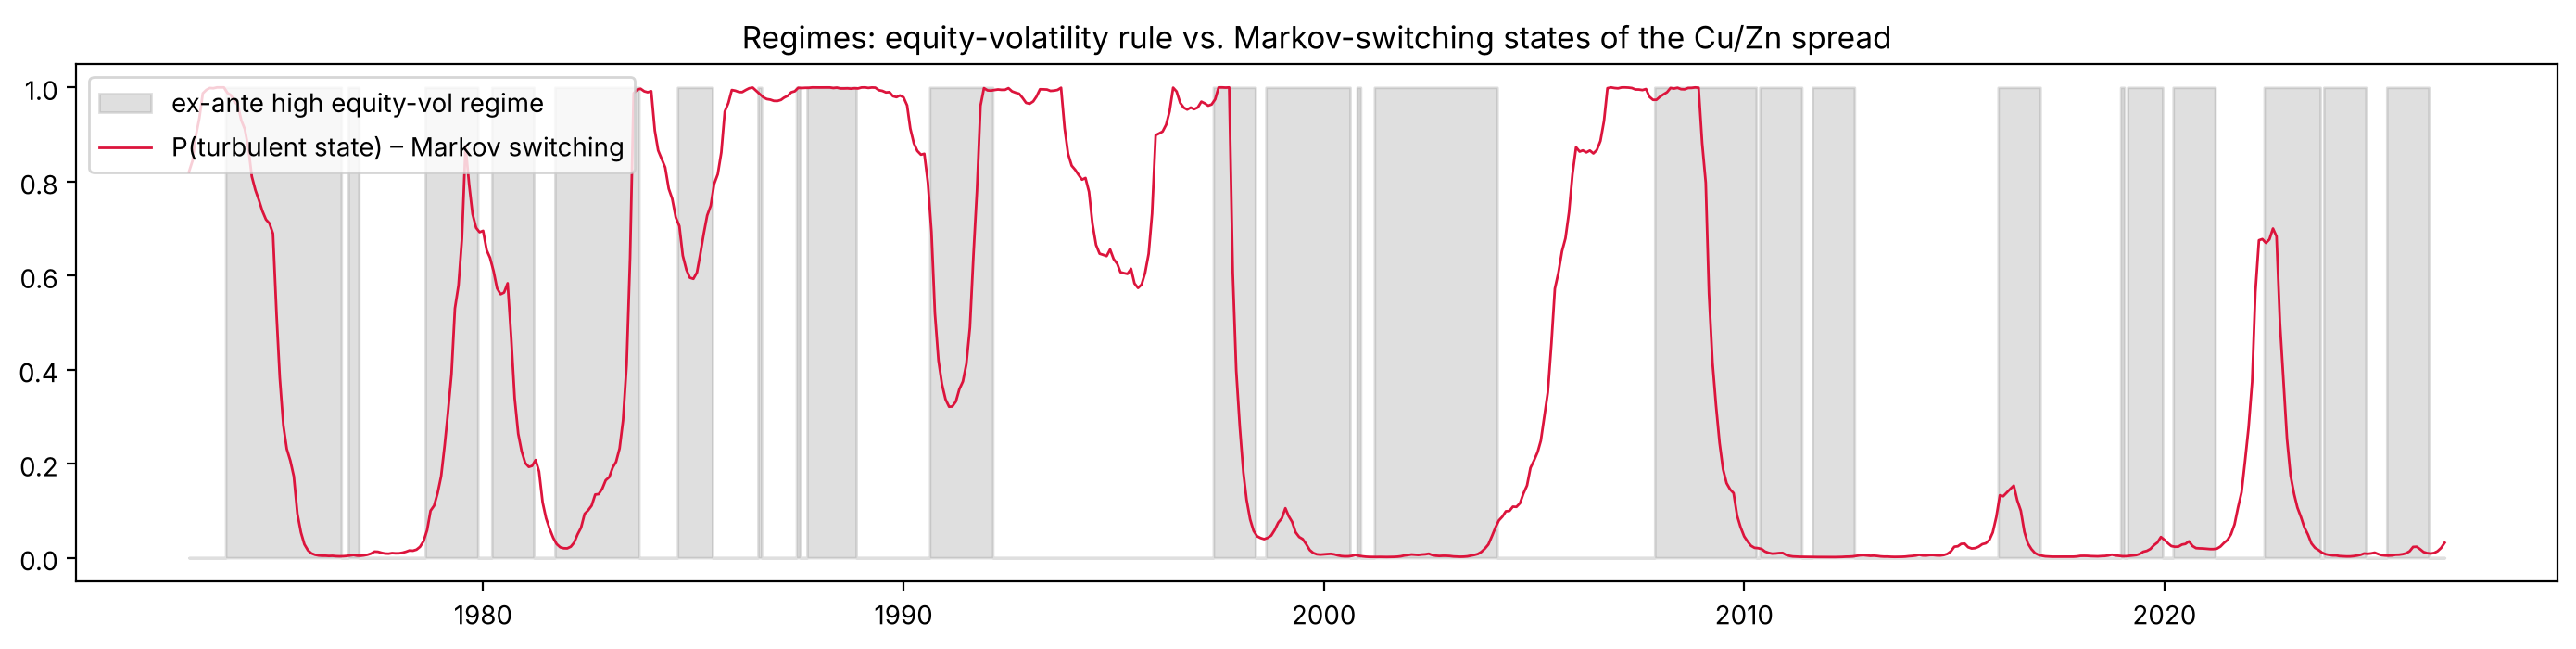

In [18]:
# Hamilton (1989) 2-state Markov-switching regression (returns in % for numerical stability)
dm = d3[["ds", "eq", "gold"]] * 100
ms = MarkovRegression(dm["ds"], k_regimes=2, exog=dm[["eq", "gold"]], switching_variance=True).fit(search_reps=20, disp=False)
sig2 = np.array([ms.params[f"sigma2[{k}]"] for k in range(2)])
kH, kL = int(sig2.argmax()), int(sig2.argmin())
ms_tab = pd.DataFrame({
    f"calm state": [ms.params[f"x1[{kL}]"], ms.tvalues[f"x1[{kL}]"], ms.params[f"x2[{kL}]"], ms.tvalues[f"x2[{kL}]"], np.sqrt(12 * sig2[kL]) / 100, ms.expected_durations[kL]],
    f"turbulent state": [ms.params[f"x1[{kH}]"], ms.tvalues[f"x1[{kH}]"], ms.params[f"x2[{kH}]"], ms.tvalues[f"x2[{kH}]"], np.sqrt(12 * sig2[kH]) / 100, ms.expected_durations[kH]],
}, index=["b_eq", "t_eq", "b_gold", "t_gold", "ann. vol of Δs", "expected duration (months)"])
display(ms_tab.round(3))

p_turb = ms.smoothed_marginal_probabilities[kH]
overlap = pd.crosstab(d3["high"].map({0: "eq-vol low", 1: "eq-vol high"}), (p_turb > .5).map({False: "MS calm", True: "MS turbulent"}), normalize="index")
display(overlap.round(2))
print(f"Correlation between P(turbulent spread state) and ex-ante equity vol: {p_turb.corr(vol_ex_ante.reindex(p_turb.index)):.2f}")

fig, ax = plt.subplots(figsize=(14, 3.6))
ax.fill_between(d3.index, 0, d3["high"], step="mid", color="grey", alpha=.25, label="ex-ante high equity-vol regime")
ax.plot(p_turb.index, p_turb, color="crimson", lw=1, label="P(turbulent state) – Markov switching")
ax.set_title("Regimes: equity-volatility rule vs. Markov-switching states of the Cu/Zn spread"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
R["H3"]["ms"] = ms_tab
R["H3"]["ms_corr_vol"] = p_turb.corr(vol_ex_ante.reindex(p_turb.index))

**Reading H3 — rejected.**

* Recall from H2 that, on average, the spread has **no equity beta** (copper and zinc both load ≈0.4 on the S&P 500, so the loadings cancel), but a **positive gold beta** (≈0.14, t≈3): the opposite of the risk-on/risk-off story.
* H3 does not rescue the equity story. The equity beta goes from −0.02 (calm) to +0.01 (high-vol); the interaction `d_eq` has t≈0.3, and the joint Wald test does not reject (p≈0.84). In the 6-cell robustness grid, **no** specification gives a significant `d_eq`; the sign even flips with the top-tercile threshold. The gold loading is present in both regimes (≈0.19 vs ≈0.14), so it is not a crisis effect either.
* The per-regime moments answer the Ch. 11 question: Δs is fat-tailed (excess kurtosis ≈1.4, JB≈63) and the kurtosis is **not** lower inside each equity-vol regime (1.2 and 1.5). The equity-vol split does not explain the fat tails of the spread.
* The Markov-switching model does find two very different states (annualised vol of Δs ≈13% vs ≈26%, durations of several years), but they are **not** the equity-vol regimes: 73% of high-equity-vol months are classified as *calm* for the spread, and the correlation between P(turbulent) and equity vol is slightly negative (≈−0.17). The equity beta is insignificant in both states; only the gold beta is significant in the turbulent state. The spread has its **own** turbulence (supply shocks, smelter closures, LME events), which is not a risk-on / risk-off phenomenon.

This is the course's Ch. 11 remark in a different form: non-normality at the level of a *factor* (here a relative-value spread) is driven by its own risk events, which equity volatility does not capture.

## 5. H4 – Out-of-sample predictability

> 🔑 **Key result: rejected.** Gold and equity information never beats plain mean reversion out-of-sample (3 learners, Clark–West p ≈ 0.8). The 1-month predictability of plain MR (OOS R² ≈ +7%) is the averaging artefact: it vanishes once we skip one month.


H2–H3 are in-sample, contemporaneous relations. H4 asks the question of the course's Ch. 20 (Welch & Goyal 2008): **does the information help to forecast the *next* spread change out-of-sample, better than a naive benchmark?**

**Set-up (same logic as the course's `Backtester` / `TimeSeriesSplit`).**
* Target: `Δs_{t+1}` (next-month change of log Cu/Zn). Because the Pink Sheet prices are **monthly averages**, `Δs_t` is mechanically autocorrelated (Working 1960: for a random walk, the first difference of averages has a lag-1 autocorrelation of ≈0.25). Part of any 1-month "predictability" is therefore an artefact that cannot be traded on month-end prices. We thus also report a **skip-month target** `Δs_{t+2}` — the same idea as skipping the most recent month in the course's momentum backtest (Ch. 4) — for which the averaging artefact disappears.
* Expanding window starting with 12 years of data (from 1973), re-estimated every 12 months, with a **gap** equal to the forecast lead minus one so that no training target overlaps the test period (purged walk-forward).
* Models, nested from the simplest:

| model | features | course reference |
|---|---|---|
| **HM** – historical mean | none | Welch–Goyal "unconditional" benchmark, Campbell–Thompson OOS R² |
| **MR** – plain mean reversion (OLS) | deviation of `s` from its 60-month mean, `Δs_t` | Ch. 17 contrarian / mean-reversion predictor |
| **MR+macro (OLS)** | MR + equity & gold returns (1, 3, 12 m), equity vol, equity×high-vol (H3) | Ch. 20 conditional regression |
| **MR+macro (RidgeCV)** | same, standardised, ridge with CV'd α | Ch. 5 & 7 (`StandardScaler` + `RidgeCV`), Ch. 20 timing pipeline |
| **MR+macro (HistGB)** | same, shallow boosted trees | Ch. 6 (boosted trees / LightGBM) |

* Evaluation: OOS R² vs HM and vs MR; **Clark–West** (2007) test for nested models (HAC); Spearman **IC** by calendar year; hit rate.

In [19]:
def make_features(a, b, lead_vol=vol_ex_ante, hi=high):
    s_ = lev[a] - lev[b]; ds_ = s_.diff()
    X = pd.DataFrame({
        "dev60": s_ - s_.rolling(60).mean(), "ds": ds_,
        "eq": rets["eq"], "gold": rets["gold"],
        "eq3": rets["eq"].rolling(3).sum(), "gold3": rets["gold"].rolling(3).sum(),
        "eq12": rets["eq"].rolling(12).sum(), "gold12": rets["gold"].rolling(12).sum(),
        "vol_eq": lead_vol.shift(-1),            # vol of the 12 months up to t (known at t)
        "eq_x_high": rets["eq"] * hi.shift(-1),  # H3 interaction, known at t
    })
    return X, ds_

# Working (1960) check: differences of monthly averages of a random walk have lag-1 autocorrelation ≈ 0.25 and ≈ 0 beyond
ac = pd.Series({f"lag {k}": rets["ds"].loc[CFG["start"]:].autocorr(k) for k in [1, 2, 3, 12]})
print("Autocorrelation of Δs (1973–):", ac.round(3).to_dict(), "  — Working benchmark for lag 1: 0.25")
R["H4_autocorr"] = ac

BASE = ["dev60", "ds"]
MACRO = BASE + ["eq", "gold", "eq3", "gold3", "eq12", "gold12", "vol_eq", "eq_x_high"]
MODELS = {
    "HM": (lambda: DummyRegressor(strategy="mean"), BASE),
    "MR": (lambda: LinearRegression(), BASE),
    "MR+macro OLS": (lambda: LinearRegression(), MACRO),
    "MR+macro Ridge": (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25))), MACRO),
    "MR+macro HistGB": (lambda: HistGradientBoostingRegressor(max_depth=2, learning_rate=0.05, max_iter=150, min_samples_leaf=40,
                                                               l2_regularization=1.0, random_state=SEED), MACRO),
}

def walk_forward(X, y, make_model, start, gap=0):
    d = pd.concat([X, y.rename("y")], axis=1).loc[start:].dropna()
    Xv, yv = d.drop(columns="y").values, d["y"].values
    n_splits = (len(d) - CFG["min_train"] - gap) // CFG["refit"]
    cv = TimeSeriesSplit(n_splits=n_splits, test_size=CFG["refit"], gap=gap)
    pred, est = pd.Series(np.nan, index=d.index), []
    for tr, te in cv.split(Xv):
        m = make_model().fit(Xv[tr], yv[tr]); pred.iloc[te] = m.predict(Xv[te]); est.append((d.index[te[0]], m))
    return pred.dropna(), d["y"], est

def oos_r2(y, p, bench): return 1 - ((y - p) ** 2).sum() / ((y - bench) ** 2).sum()
def clark_west(y, p_small, p_big, lags):
    f = (y - p_small) ** 2 - ((y - p_big) ** 2 - (p_small - p_big) ** 2)
    m = sm.OLS(f.values, np.ones(len(f))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return m.tvalues[0], 1 - stats.norm.cdf(m.tvalues[0])
def yearly_ic(y, p):
    ic = pd.concat([y, p], axis=1).groupby(y.index.year).apply(lambda g: stats.spearmanr(g.iloc[:, 0], g.iloc[:, 1])[0])
    return ic.mean(), ic.mean() / ic.std() * np.sqrt(len(ic))

def run_oos(a="cu", b="zn", lead=1, start=CFG["start"], models=MODELS):
    X, ds_ = make_features(a, b)
    y = ds_.shift(-lead).rename("y")
    preds, est = {}, {}
    for k, (mk, cols) in models.items():
        preds[k], yy, est[k] = walk_forward(X[cols], y, mk, start, gap=lead - 1)
    P = pd.DataFrame(preds).dropna(); yy = yy.reindex(P.index)
    rows = {}
    for k in models:
        cw_hm = clark_west(yy, P["HM"], P[k], lead + 2) if k != "HM" else (np.nan, np.nan)
        cw_mr = clark_west(yy, P["MR"], P[k], lead + 2) if k not in ("HM", "MR") else (np.nan, np.nan)
        ic, ic_t = yearly_ic(yy, P[k]) if k != "HM" else (np.nan, np.nan)
        rows[k] = dict(R2_oos_vs_HM=oos_r2(yy, P[k], P["HM"]), CW_p_vs_HM=cw_hm[1],
                       R2_oos_vs_MR=oos_r2(yy, P[k], P["MR"]), CW_p_vs_MR=cw_mr[1],
                       IC=ic, IC_t=ic_t, hit=(np.sign(P[k]) == np.sign(yy)).mean())
    return pd.DataFrame(rows).T, P, yy, est

oos = {}
for lead in [1, 2]:
    tab, P, yy, est = run_oos(lead=lead)
    oos[lead] = dict(tab=tab, P=P, y=yy, est=est)
    print(f"Target Δs(t+{lead})  —  OOS period {P.index[0]:%Y-%m} → {P.index[-1]:%Y-%m}, n = {len(P)}")
    display(tab.round(4))
R["H4"] = {l: oos[l]["tab"] for l in oos}

Autocorrelation of Δs (1973–): {'lag 1': 0.259, 'lag 2': 0.005, 'lag 3': -0.016, 'lag 12': 0.054}   — Working benchmark for lag 1: 0.25


Target Δs(t+1)  —  OOS period 1985-09 → 2026-08, n = 492


,R2_oos_vs_HM,CW_p_vs_HM,R2_oos_vs_MR,CW_p_vs_MR,IC,IC_t,hit
HM,0.0000,NaN,-0.0791,NaN,NaN,NaN,0.4431
MR,0.0733,0.0000,0.0000,NaN,0.0570,1.0923,0.6016
MR+macro OLS,0.0178,0.0008,-0.0599,0.7920,0.0838,1.7332,0.5589
MR+macro Ridge,0.0383,0.0001,-0.0378,0.7818,0.0470,0.9286,0.5589
MR+macro HistGB,-0.0390,0.0328,-0.1212,0.8880,-0.0206,-0.4274,0.5386


Target Δs(t+2)  —  OOS period 1985-08 → 2026-07, n = 492


,R2_oos_vs_HM,CW_p_vs_HM,R2_oos_vs_MR,CW_p_vs_MR,IC,IC_t,hit
HM,0.0000,NaN,0.0066,NaN,NaN,NaN,0.4553
MR,-0.0066,0.4453,0.0000,NaN,0.1235,2.5314,0.4776
MR+macro OLS,-0.0853,0.9843,-0.0781,0.9826,-0.0665,-1.2893,0.4776
MR+macro Ridge,-0.0012,0.9829,0.0054,0.1263,-0.0928,-1.9423,0.4431
MR+macro HistGB,-0.1197,0.9410,-0.1123,0.9276,-0.0322,-0.6738,0.4797


**Cumulative OOS R² (Welch–Goyal style plot).** The course stresses that in-sample predictability of the S&P 500 (dividend yield…) disappears out-of-sample and that results depend heavily on a few episodes (the 1974 oil shock). The plot below shows the **cumulative difference in squared errors** of each model versus the MR benchmark: a line drifting up means the macro information keeps helping; a line that jumps once and then decays means the gain comes from one episode.

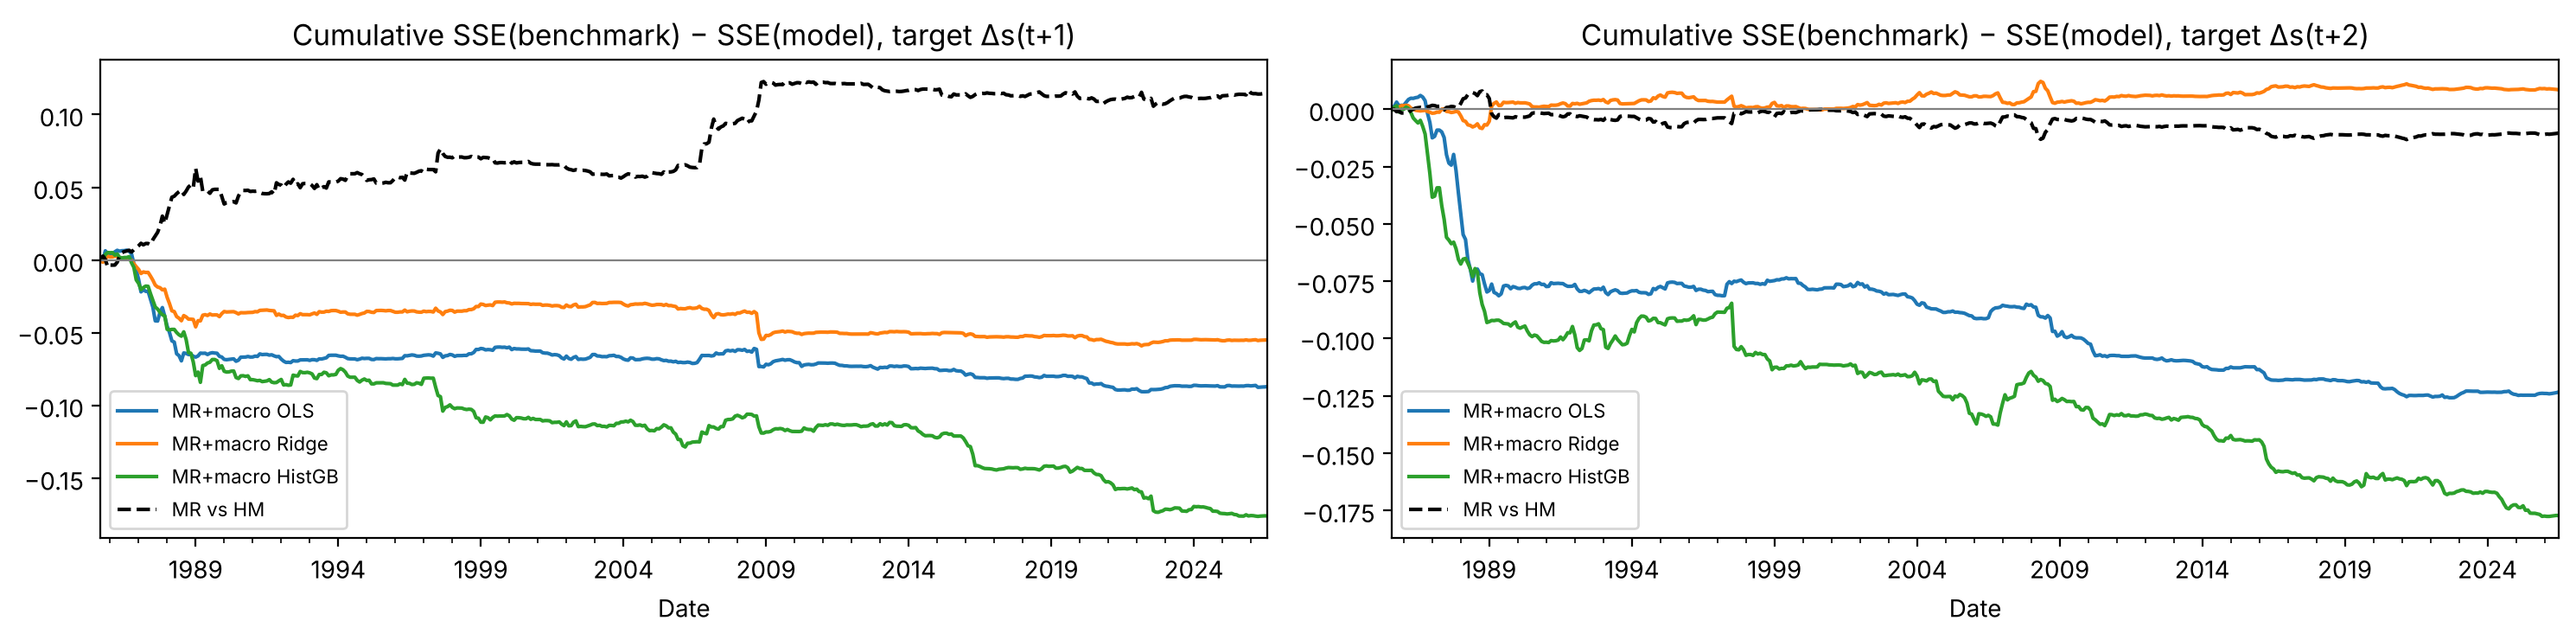

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
for a, lead in zip(ax, [1, 2]):
    P, yy = oos[lead]["P"], oos[lead]["y"]
    for k in ["MR+macro OLS", "MR+macro Ridge", "MR+macro HistGB"]:
        ((yy - P["MR"]) ** 2 - (yy - P[k]) ** 2).cumsum().plot(ax=a, label=k)
    ((yy - P["HM"]) ** 2 - (yy - P["MR"]) ** 2).cumsum().plot(ax=a, label="MR vs HM", color="k", ls="--")
    a.axhline(0, c="grey", lw=.8); a.set_title(f"Cumulative SSE(benchmark) − SSE(model), target Δs(t+{lead})"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.1 From forecasts to an (illustrative) trading rule – the course's backtest checklist

To go from statistical to economic significance, we map forecasts to a **long copper / short zinc** position, following the course's single-asset timing logic (`TimingMeanVariance`, Ch. 3.3.6 and Ch. 20): the position is proportional to the forecast divided by the risk, clipped to cap leverage, and scaled to an ex-ante volatility target of 10% a year (Ch. 3.3.4 *risk targeting*):

`h_t = clip(ŷ_t / std_past(ŷ), −2, 2) × σ_target / σ̂_t(Δs)`, with σ̂ the 36-month realised vol known at *t*.

PnL: `pnl_{t+L} = h_t · Δs_{t+L}` (lag *L* = forecast lead), i.e. `h.shift(L).mul(ret)` exactly as in the course. Costs follow Ch. 15: turnover `|h_t − h_{t−1}|`, paid on **two legs**, at 0/5/10/25 bp per leg.

⚠️ This is an illustration, not a tradable backtest: the Pink Sheet gives monthly **average** prices, so the 1-month version partly trades on the averaging artefact; the skip-month version is the more honest one.

SR @ 0bp  SR @ 5bp  SR @ 10bp  SR @ 25bp
target model                                                    
t+1    MR                   0.66      0.60       0.54       0.37
       MR+macro HistGB      0.21      0.16       0.10      -0.06
       MR+macro OLS         0.47      0.41       0.35       0.17
       MR+macro Ridge       0.46      0.40       0.34       0.16
t+2    MR                  -0.07     -0.09      -0.11      -0.16
       MR+macro HistGB     -0.22     -0.27      -0.31      -0.45
       MR+macro OLS        -0.52     -0.55      -0.59      -0.70
       MR+macro Ridge      -0.35     -0.36      -0.37      -0.40

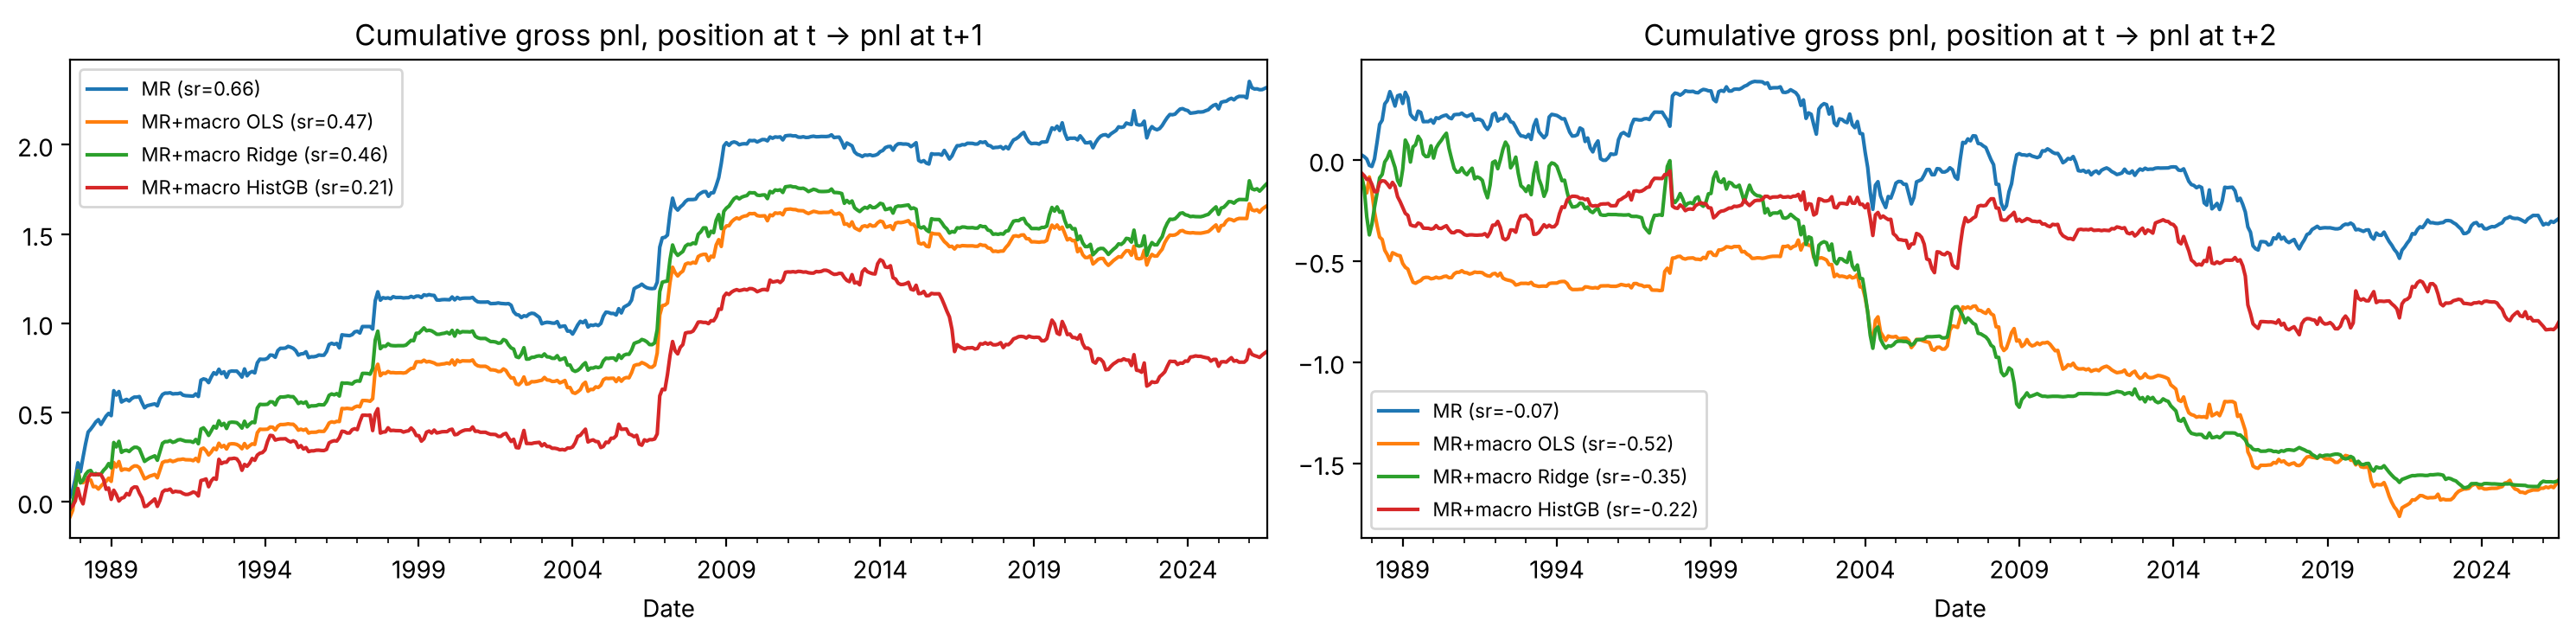

In [21]:
def sharpe_ratio(x, n=12):          # course Ch. 27 (skfin.metrics.sharpe_ratio)
    x = x.replace(0, np.nan).dropna(); return x.mean() / x.std() * np.sqrt(n)
def drawdown(x, window=36, n=12):    # course Ch. 27, in units of annualised risk
    dd = x.cumsum() - x.cumsum().cummax(); return dd / (x.rolling(window).std() * np.sqrt(n))
def stationary_bootstrap_sr(x, B=2000, p=1 / 12):   # Politis & Romano (1994), mean block = 12 months
    x = np.asarray(x.dropna()); n = len(x); out = np.empty(B)
    for b in range(B):
        idx = np.empty(n, int); idx[0] = rng.integers(n)
        for i in range(1, n): idx[i] = rng.integers(n) if rng.random() < p else (idx[i - 1] + 1) % n
        xb = x[idx]; out[b] = xb.mean() / xb.std() * np.sqrt(12)
    return np.percentile(out, [5, 50, 95])

def positions(pred, ds_, clip=2.0):
    z = (pred / pred.expanding(24).std()).clip(-clip, clip)
    sig = ds_.rolling(36).std().reindex(pred.index)
    return (z * CFG["target_vol"] / np.sqrt(12) / sig).dropna()

def strategy(pred, ds_, lead, c_bps=0):
    h = positions(pred, ds_)
    gross = h.shift(lead).mul(ds_).dropna()
    cost = 2 * c_bps / 1e4 * h.diff().abs().shift(lead)
    return h, (gross - cost.reindex(gross.index).fillna(0))

ds_cz = make_features("cu", "zn")[1]
rows, PNL = [], {}
for lead in [1, 2]:
    for k in ["MR", "MR+macro OLS", "MR+macro Ridge", "MR+macro HistGB"]:
        for c in CFG["costs_bps"]:
            h, pnl = strategy(oos[lead]["P"][k], ds_cz, lead, c)
            if c == 0: PNL[(lead, k)] = pnl
            rows.append(dict(target=f"t+{lead}", model=k, cost_bps=c, SR=sharpe_ratio(pnl)))
sr_tab = pd.DataFrame(rows).pivot_table(index=["target", "model"], columns="cost_bps", values="SR")
sr_tab.columns = [f"SR @ {c}bp" for c in sr_tab.columns]
display(sr_tab.round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
for a, lead in zip(ax, [1, 2]):
    for k in ["MR", "MR+macro OLS", "MR+macro Ridge", "MR+macro HistGB"]:
        p = PNL[(lead, k)]; p.cumsum().plot(ax=a, label=f"{k} (sr={sharpe_ratio(p):.2f})")
    a.set_title(f"Cumulative gross pnl, position at t → pnl at t+{lead}"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
R["H4"]["sr"] = sr_tab

### 5.2 Course diagnostics on the Ridge strategy

We now apply to the pre-specified **MR+macro Ridge** strategy the diagnostics that the course applies to its industry-momentum (Ch. 4, 11, 15) and S&P-timing (Ch. 20) backtests, in both versions (1-month and skip-month):

1. **Lead-lag Sharpe ratio** (Ch. 4): horizon 0 = tradable pnl; positive lags = alpha decay; negative lags = non-tradable counterfactual. The course notes that *trending* predictors have high lead Sharpe ratios while *contrarian* ones have negative ones.
2. **Tilt / timing decomposition** (Ch. 13 & 20): slow position (EWMA, 12-month half-life) vs. the residual timing position.
3. **Non-normality and the 3-year rolling Sharpe ratio** with the Lo (2002) and Mertens (2002) lower bounds (Ch. 11).
4. **Maximum drawdown in units of annualised risk** (Ch. 27 — normalised here by the full-sample vol, because the course's rolling-vol normalisation explodes when the position is close to zero for a few years) and **stationary-bootstrap** confidence interval for the Sharpe ratio.
5. **Turnover and holding period** (Ch. 15): `HP = mean |h| / mean turnover`.
6. **Robustness**: ridge-α sweep and **feature off-the-top** (Ch. 4 & 20).
7. **Style analysis** (Ch. 12): is the pnl just a disguised exposure to equities, gold or one of the two metals?

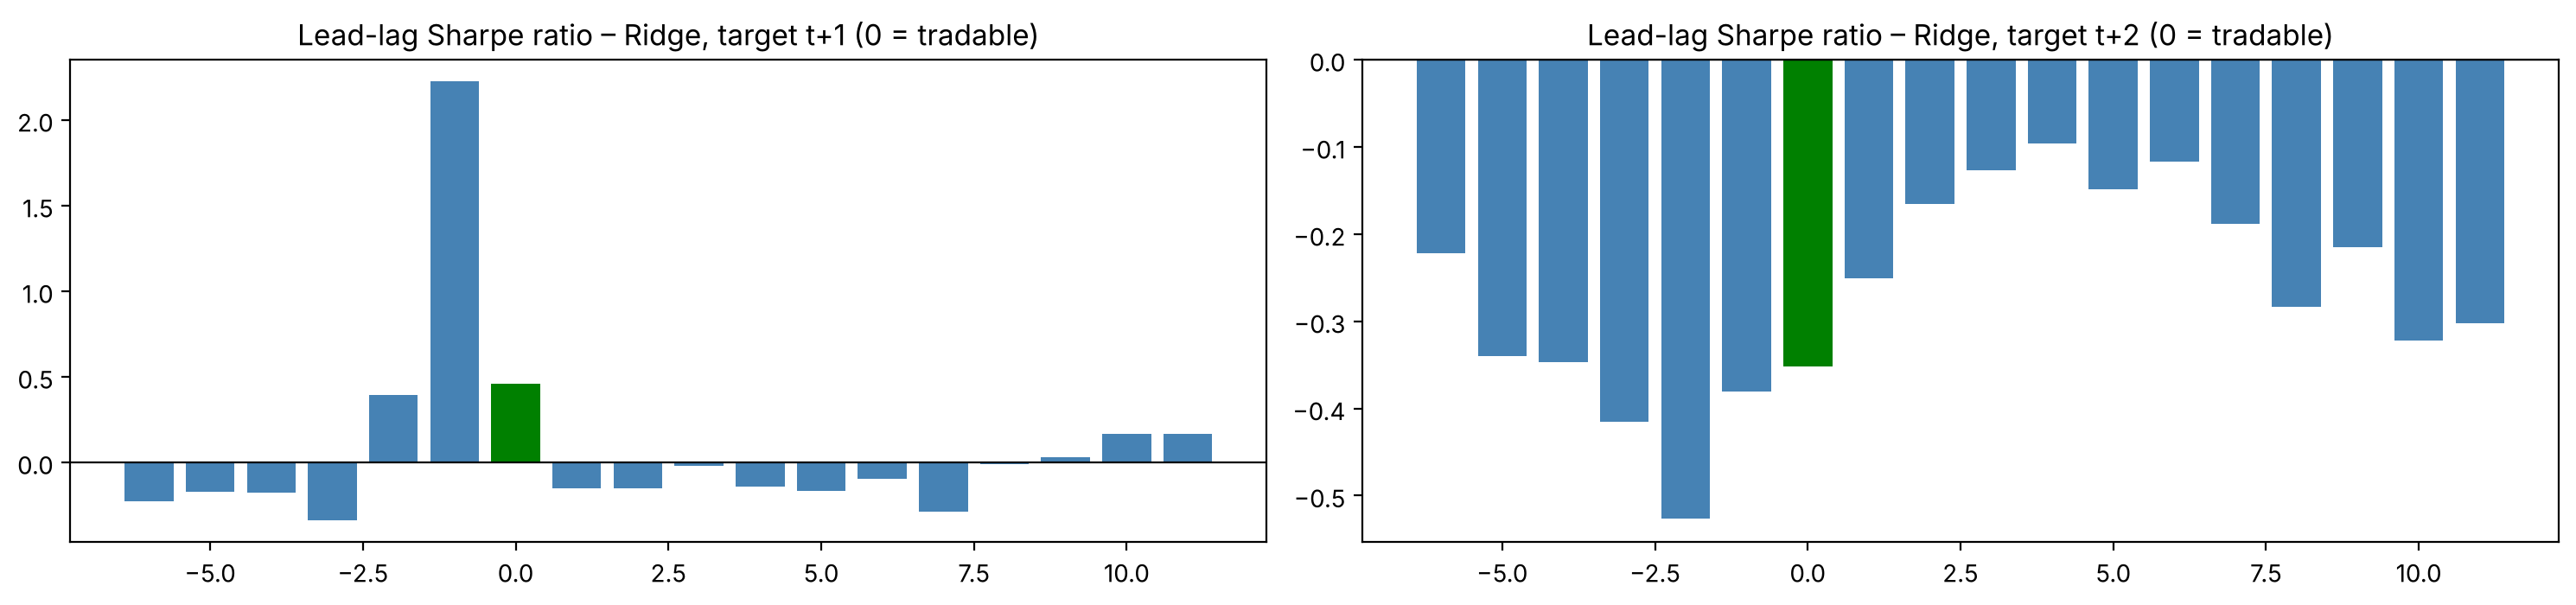

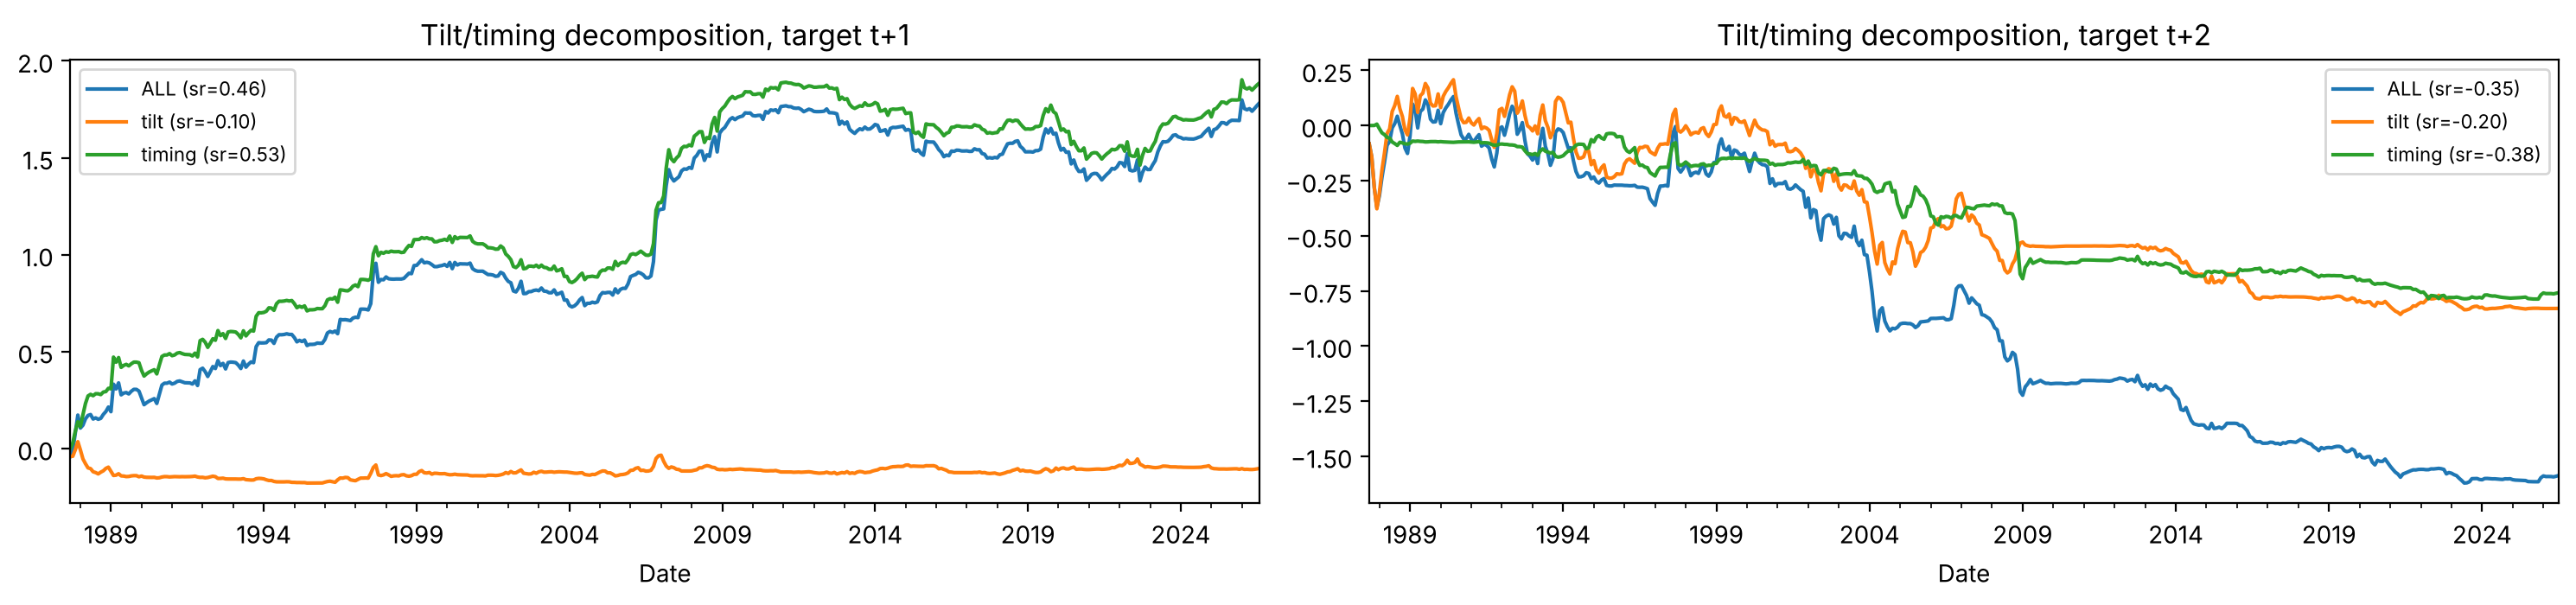

In [22]:
KEY = "MR+macro Ridge"
H, PN = {}, {}
for lead in [1, 2]:
    H[lead], PN[lead] = strategy(oos[lead]["P"][KEY], ds_cz, lead)

fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
for a, lead in zip(ax, [1, 2]):
    h = H[lead]
    sr = {i: sharpe_ratio(h.shift(lead + i).mul(ds_cz).dropna()) for i in range(-6, 12)}
    a.bar(list(sr), list(sr.values()), color=["green" if i == 0 else "steelblue" for i in sr])
    a.set_title(f"Lead-lag Sharpe ratio – Ridge, target t+{lead} (0 = tradable)"); a.axhline(0, c="k", lw=.8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
for a, lead in zip(ax, [1, 2]):
    h = H[lead]; tilt = h.ewm(halflife=12).mean()
    parts = {"ALL": h.shift(lead).mul(ds_cz), "tilt": tilt.shift(lead).mul(ds_cz), "timing": (h - tilt).shift(lead).mul(ds_cz)}
    for k, v in parts.items():
        v = v.dropna(); v.cumsum().plot(ax=a, label=f"{k} (sr={sharpe_ratio(v):.2f})")
    a.set_title(f"Tilt/timing decomposition, target t+{lead}"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

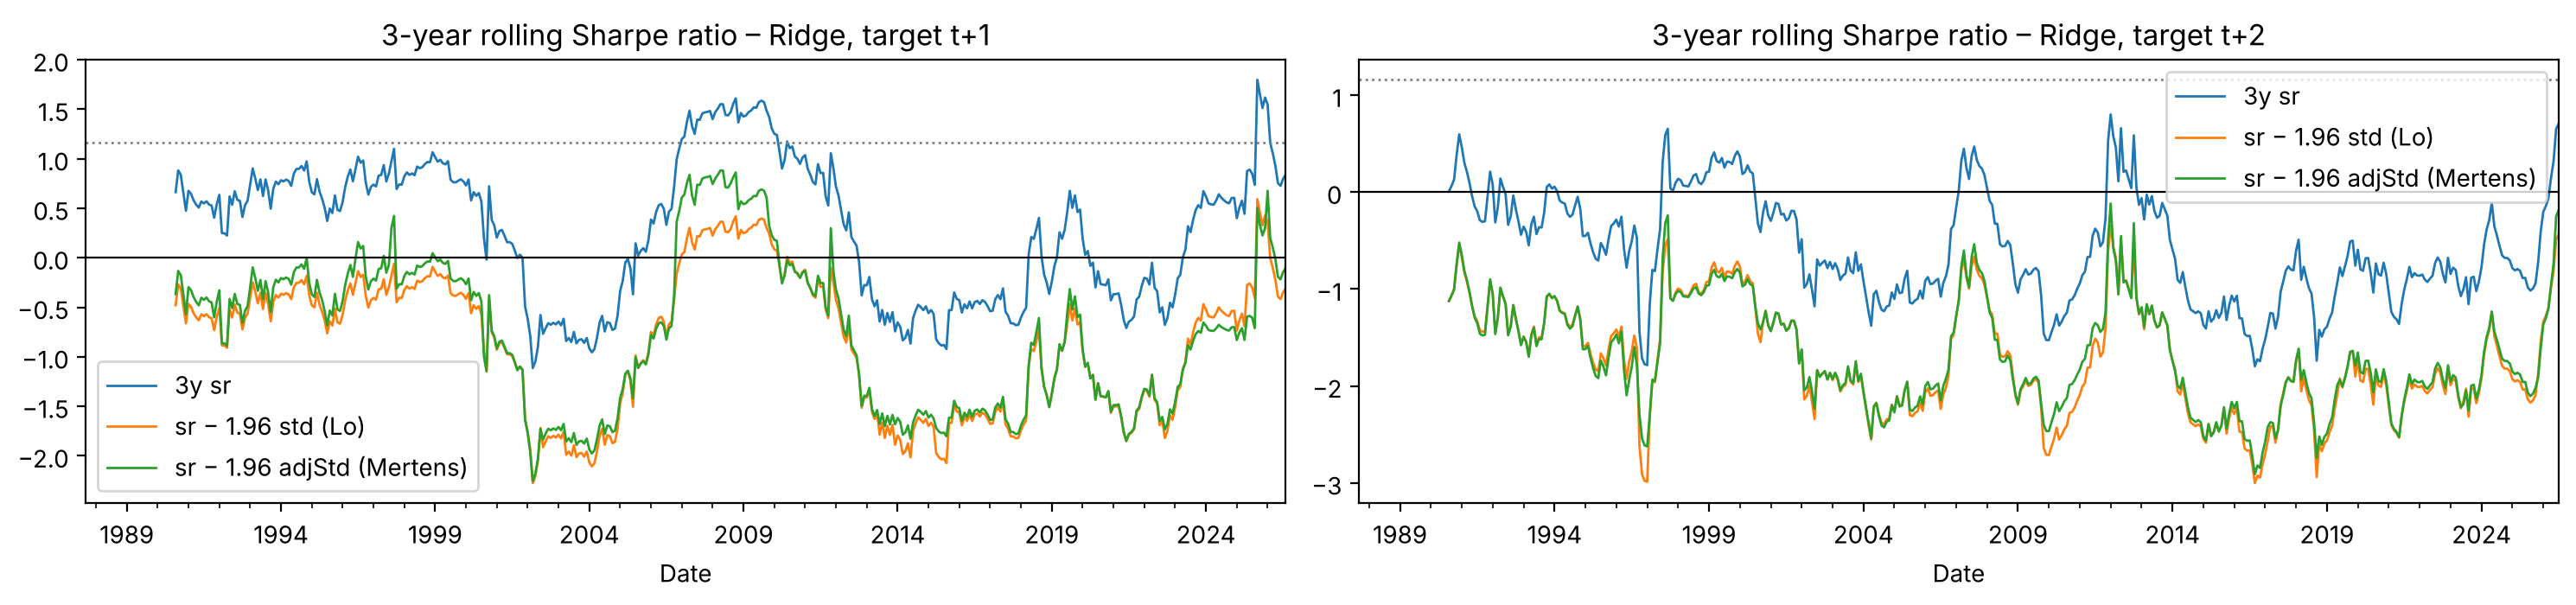

,t+1,t+2
SR,0.461269,-0.351886
SR_boot_5,0.184127,-0.612232
SR_boot_95,0.718663,-0.118826
skew,1.518586,-0.160352
exc_kurt,10.886418,5.282642
JB,2490.901103,545.011486
share_3y_SR_below_0,0.324786,0.749465
share_3y_SR_signif,0.119658,0.0
max_DD_in_ann_vol,-3.908222,-15.12499
SR_tilt,-0.097555,-0.196207


In [23]:
rows = {}
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
for a, lead in zip(ax, [1, 2]):
    x = PN[lead]
    sr3y = x.rolling(36).apply(sharpe_ratio)
    sk3y, ku3y = x.rolling(36).apply(stats.skew), x.rolling(36).apply(stats.kurtosis)
    srm = sr3y / np.sqrt(12)                                                       # monthly SR for the formulas
    lb_lo = sr3y - 1.96 * np.sqrt((1 + 0.5 * srm ** 2) / 36) * np.sqrt(12)
    lb_me = sr3y - 1.96 * np.sqrt((1 + 0.5 * srm ** 2 - sk3y * srm + 0.25 * ku3y * srm ** 2) / 36) * np.sqrt(12)
    pd.DataFrame({"3y sr": sr3y, "sr − 1.96 std (Lo)": lb_lo, "sr − 1.96 adjStd (Mertens)": lb_me}).plot(ax=a, lw=1)
    a.axhline(0, c="k", lw=.8); a.axhline(1.16, c="grey", ls=":", lw=1)   # course rule of thumb (Lo): SR needed over 36 months
    a.set_title(f"3-year rolling Sharpe ratio – Ridge, target t+{lead}")
    hp = H[lead].abs().mean() / H[lead].diff().abs().mean()
    ci = stationary_bootstrap_sr(x)
    rows[f"t+{lead}"] = dict(SR=sharpe_ratio(x), SR_boot_5=ci[0], SR_boot_95=ci[2], skew=stats.skew(x), exc_kurt=stats.kurtosis(x),
                             JB=stats.jarque_bera(x).statistic, share_3y_SR_below_0=(sr3y < 0).mean(),
                             share_3y_SR_signif=(lb_me > 0).mean(),
                             max_DD_in_ann_vol=(x.cumsum() - x.cumsum().cummax()).min() / (x.std() * np.sqrt(12)),
                             SR_tilt=sharpe_ratio(H[lead].ewm(halflife=12).mean().shift(lead).mul(ds_cz).dropna()),
                             SR_timing=sharpe_ratio((H[lead] - H[lead].ewm(halflife=12).mean()).shift(lead).mul(ds_cz).dropna()),
                             SR_lead_minus1=sharpe_ratio(H[lead].shift(lead - 1).mul(ds_cz).dropna()),
                             SR_lag_plus1=sharpe_ratio(H[lead].shift(lead + 1).mul(ds_cz).dropna()),
                             holding_period_months=hp, worst_month=x.min(), worst_month_date=x.idxmin().strftime("%Y-%m"))
plt.tight_layout(); plt.show()
diag = pd.DataFrame(rows).T
display(diag.round(3).T)
R["H4"]["diag"] = diag

SR        R2_vs_MR       
target            t+1    t+2      t+1    t+2
test                                        
alpha=0.1       0.469 -0.518   -0.060 -0.078
alpha=1         0.469 -0.517   -0.058 -0.077
alpha=10        0.470 -0.509   -0.049 -0.067
alpha=100       0.470 -0.503   -0.035 -0.032
alpha=1000      0.361 -0.485   -0.056 -0.003
alpha=10000    -0.025 -0.352   -0.075  0.005
drop dev60      0.486 -0.357   -0.034  0.005
drop ds        -0.222 -0.342   -0.099  0.006
drop eq         0.453 -0.351   -0.038  0.006
drop gold       0.458 -0.352   -0.037  0.005
drop eq3        0.461 -0.332   -0.042  0.005
drop gold3      0.462 -0.346   -0.039  0.005
drop eq12       0.483 -0.352   -0.034  0.006
drop gold12     0.508 -0.318   -0.030  0.006
drop vol_eq     0.515 -0.317   -0.030  0.006
drop eq_x_high  0.470 -0.350   -0.034  0.006

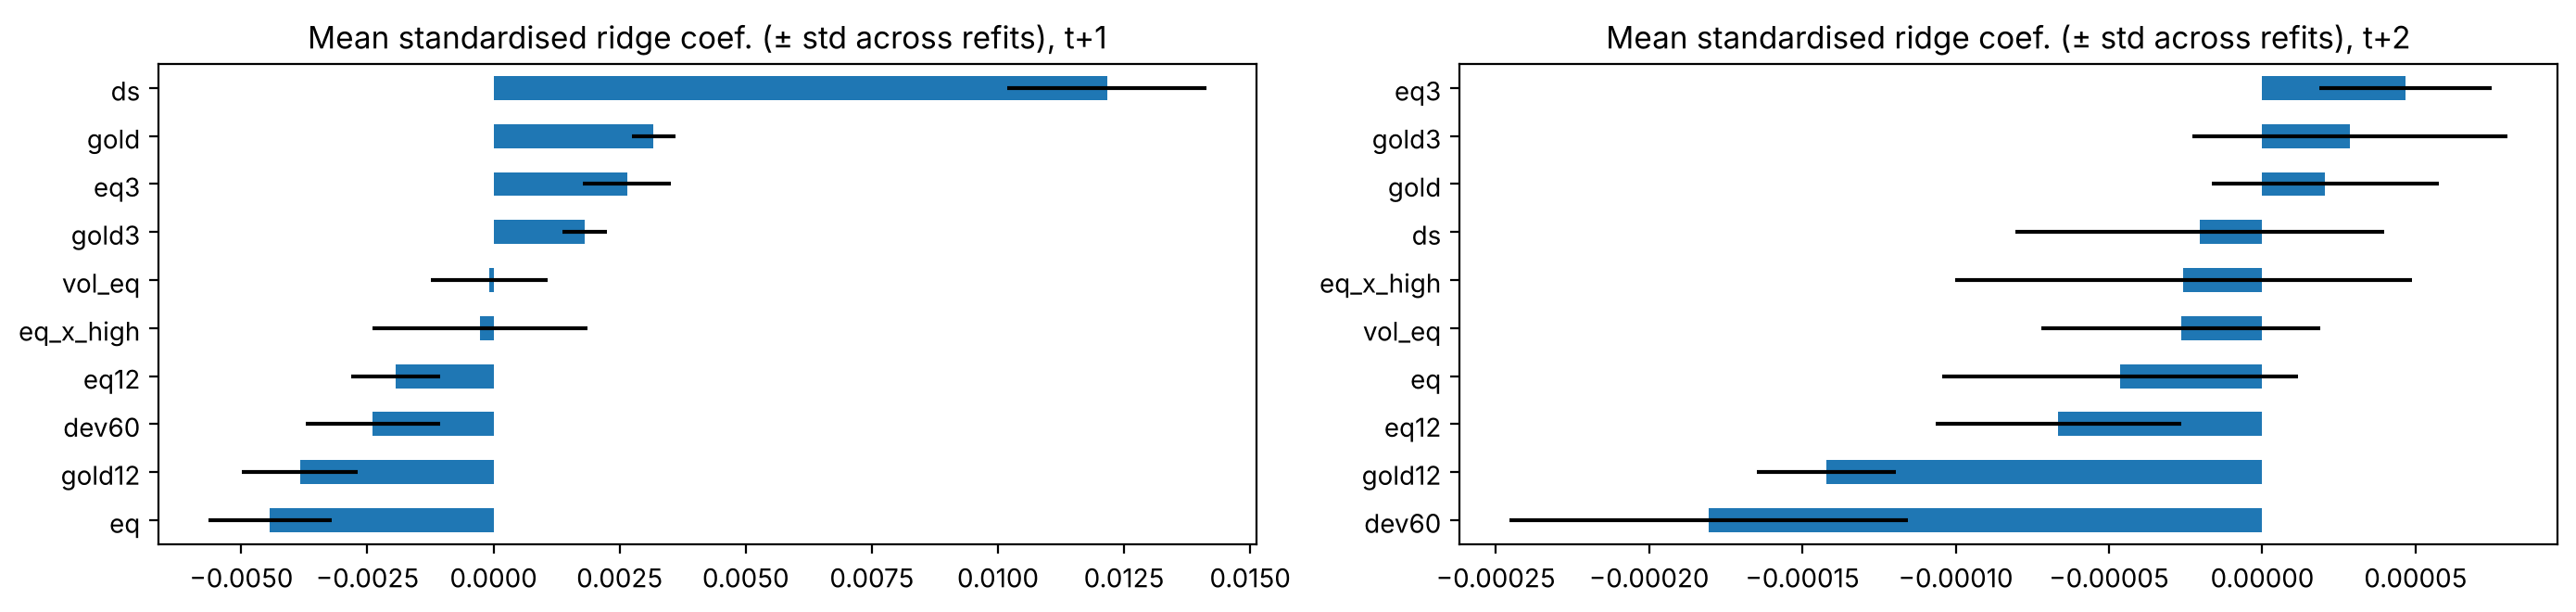

In [24]:
# Robustness: ridge alpha sweep (course Ch. 20) and feature off-the-top (course Ch. 4/20), target t+1 and t+2
X_cz, _ = make_features("cu", "zn")
rows = []
for lead in [1, 2]:
    y = ds_cz.shift(-lead)
    for alpha in [0.1, 1, 10, 100, 1000, 10000]:
        p, yy, _ = walk_forward(X_cz[MACRO], y, lambda a=alpha: make_pipeline(StandardScaler(), Ridge(alpha=a)), CFG["start"], gap=lead - 1)
        rows.append(dict(target=f"t+{lead}", test=f"alpha={alpha:g}", SR=sharpe_ratio(strategy(p, ds_cz, lead)[1]),
                         R2_vs_MR=oos_r2(yy.reindex(p.index), p, oos[lead]["P"]["MR"].reindex(p.index))))
    for c in MACRO:
        cols = [k for k in MACRO if k != c]
        p, yy, _ = walk_forward(X_cz[cols], y, MODELS[KEY][0], CFG["start"], gap=lead - 1)
        rows.append(dict(target=f"t+{lead}", test=f"drop {c}", SR=sharpe_ratio(strategy(p, ds_cz, lead)[1]),
                         R2_vs_MR=oos_r2(yy.reindex(p.index), p, oos[lead]["P"]["MR"].reindex(p.index))))
rob4 = pd.DataFrame(rows).pivot_table(index="test", columns="target", values=["SR", "R2_vs_MR"], sort=False)
display(rob4.round(3))
R["H4"]["rob"] = rob4

# Average standardised ridge coefficients (course Ch. 20 "Ridge coefficient" bar plot)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.4))
for a, lead in zip(ax, [1, 2]):
    coef = pd.DataFrame([m.steps[1][1].coef_ for _, m in oos[lead]["est"][KEY]], columns=MACRO,
                        index=[d for d, _ in oos[lead]["est"][KEY]])
    coef.mean().sort_values().plot.barh(ax=a, xerr=coef.std(), title=f"Mean standardised ridge coef. (± std across refits), t+{lead}")
plt.tight_layout(); plt.show()

In [25]:
# Style analysis of the strategy pnl (course Ch. 12): pnl_t = alpha + b·factors_t + e
rows = {}
for lead in [1, 2]:
    d = pd.concat([PN[lead].rename("pnl"), rets[["eq", "gold", "cu", "zn"]]], axis=1).dropna()
    m = hac(d["pnl"], d[["eq", "gold", "cu", "zn"]], 6)
    rows[f"t+{lead}"] = pd.concat([m.params.rename(lambda i: f"coef {i}"), m.tvalues.rename(lambda i: f"t {i}"),
                                   pd.Series({"R2": m.rsquared, "alpha (ann. %)": 1200 * m.params["const"]})])
style = pd.DataFrame(rows)
display(style.round(3))
R["H4"]["style"] = style

,t+1,t+2
coef const,0.004,-0.003
coef eq,-0.049,0.050
coef gold,0.078,-0.056
coef cu,-0.058,-0.401
coef zn,0.110,0.416
t const,2.554,-2.230
t eq,-0.912,1.126
t gold,1.890,-1.418
t cu,-0.969,-5.192
t zn,1.969,7.266


**Reading H4 — rejected (the gold/equity information has no out-of-sample value).**

* **1-month target.** The only model that clearly beats the historical mean is plain **MR** (OOS R² ≈ +7%, Clark–West p < 0.001, hit rate 60%). Almost all of it comes from the `Δs_t` feature, i.e. the Working effect: the lag-1 autocorrelation of Δs is ≈0.25, exactly the theoretical value for averages of a random walk, and dropping `ds` turns the Ridge Sharpe ratio from ≈0.46 to ≈−0.2. Adding gold and equity information **worsens** the forecasts: OOS R² vs MR is negative for OLS (≈−6%), Ridge (≈−4%) and boosted trees (≈−12%), and Clark–West never rejects (p ≈ 0.78–0.89).
* **Skip-month target** (no averaging effect). Nothing beats the historical mean. The Ridge OOS R² vs MR is ≈+0.5% (CW p≈0.13): not significant and economically zero. The skip-month strategy loses money (SR≈−0.35, bootstrap 90% CI entirely below 0). The style regression shows why: it is mostly a **static short-copper / long-zinc tilt** (R²≈48% on the two metal returns) during the long rise of Cu/Zn after 2003.
* **Course diagnostics on the 1-month Ridge strategy.** The lead-lag profile is that of a *trending* predictor (Ch. 4): very high Sharpe if the information were available one month earlier (≈2.2), ≈0.46 when tradable, and ≤0 from the next lag on. The pnl comes from **timing** (≈0.53), not from the **tilt** (≈−0.1) (Ch. 13/20). It is very non-normal (skew ≈1.5, excess kurtosis ≈11), and the 3-year Sharpe is significant only ≈12% of the time with the Mertens bound. Its holding period is below one month, so costs matter: SR ≈0.46 → 0.34 at 10 bp → 0.16 at 25 bp per leg. Its style alpha (≈4%/yr, t≈2.6) cannot be explained by equity, gold, copper or zinc returns, but that alpha is the averaging artefact. It would not survive on month-end prices.

## 6. H5 – Is Cu/Zn special? Other LME pairs

> 🔑 **Key result: Cu/Zn is not special.** All six pairs show slow (25–40-month half-life) and fragile mean reversion, small pair-specific macro loadings and no regime effect, and macro information hurts OOS forecasts for 6/6 pairs.


We re-run the core of H1–H4 on five other pairs — Cu/Al, Cu/Ni, Zn/Pb, Al/Zn, Ni/Zn — **and on Cu/Zn itself on the same 1980–today window**, so that differences reflect the pair, not the sample. This is the cross-sectional version of the course's off-the-top idea (Ch. 4): if a result only holds for one pair out of six, it is more likely a sample accident than an economic regularity (the multiple-testing problem the course raises when discussing hyper-parameter search, Ch. 7).

For each pair: cointegration (ADF on the log ratio, KPSS, Engle–Granger, Johansen), half-life, share of rolling windows that look stationary, HAC betas on equity and gold (1 and 12 months), the H3 high-vol interaction, and the H4 out-of-sample statistics of the Ridge model.

In [26]:
PAIRS = [("cu", "zn"), ("cu", "al"), ("cu", "ni"), ("zn", "pb"), ("al", "zn"), ("ni", "zn")]
S5 = CFG["lme_start"]
MODELS5 = {k: MODELS[k] for k in ["HM", "MR", "MR+macro Ridge"]}

def pair_summary(a, b):
    la, lb = lev[a].loc[S5:], lev[b].loc[S5:]; s_ = la - lb; ds_ = s_.diff()
    out = {}
    out["ADF_p"] = adfuller(s_, regression="c", autolag="AIC")[1]
    out["KPSS_p"] = kpss(s_, regression="c", nlags="auto")[1]
    out["EG_p"] = coint(la, lb, trend="c", autolag="aic")[1]
    jo_ = coint_johansen(pd.concat([la, lb], axis=1), det_order=0, k_ar_diff=2)
    out["Johansen_r≥1"] = bool(jo_.lr1[0] > jo_.cvt[0, 1])
    out["beta_coint"] = sm.OLS(la, sm.add_constant(lb)).fit().params.iloc[1]
    out["half_life"] = halflife(s_)[0]
    W = CFG["roll_window"]
    out["share_stationary"] = np.mean([adfuller(s_.iloc[e - W:e], regression="c", autolag="AIC")[1] < .05 for e in range(W, len(s_) + 1, 6)])
    for h in [1, 12]:
        d = pd.concat({"y": agg(ds_, h), "eq": agg(rets["eq"], h), "gold": agg(rets["gold"], h)}, axis=1).loc[S5:].dropna()
        m = hac(d["y"], d[["eq", "gold"]], h + 3)
        out[f"b_eq_{h}m"], out[f"t_eq_{h}m"] = m.params["eq"], m.tvalues["eq"]
        out[f"b_gold_{h}m"], out[f"t_gold_{h}m"] = m.params["gold"], m.tvalues["gold"]
    d = pd.concat({"ds": ds_, "eq": rets["eq"], "gold": rets["gold"], "high": high}, axis=1).loc[S5:].dropna()
    d["eq_x_high"], d["gold_x_high"] = d["eq"] * d["high"], d["gold"] * d["high"]
    m = hac(d["ds"], d[["eq", "gold", "high", "eq_x_high", "gold_x_high"]], 4)
    out["d_eq_highvol"], out["t_d_eq_highvol"] = m.params["eq_x_high"], m.tvalues["eq_x_high"]
    for lead in [1, 2]:
        tab, P, yy, _ = run_oos(a, b, lead=lead, start=S5, models=MODELS5)
        out[f"R2oos_MR_vs_HM_t+{lead}"] = tab.loc["MR", "R2_oos_vs_HM"]
        out[f"R2oos_Ridge_vs_MR_t+{lead}"] = tab.loc["MR+macro Ridge", "R2_oos_vs_MR"]
        out[f"CW_p_Ridge_vs_MR_t+{lead}"] = tab.loc["MR+macro Ridge", "CW_p_vs_MR"]
        dsx = (lev[a] - lev[b]).diff()
        out[f"SR_Ridge_t+{lead}"] = sharpe_ratio(strategy(P["MR+macro Ridge"], dsx, lead, 0)[1])
        out[f"SR_Ridge_t+{lead}_10bp"] = sharpe_ratio(strategy(P["MR+macro Ridge"], dsx, lead, 10)[1])
    return out

H5 = pd.DataFrame({f"{a.capitalize()}/{b.capitalize()}": pair_summary(a, b) for a, b in PAIRS}).T
pd.set_option("display.max_columns", 50)
display(H5[["ADF_p", "KPSS_p", "EG_p", "Johansen_r≥1", "beta_coint", "half_life", "share_stationary"]].round(3))
display(H5[["b_eq_1m", "t_eq_1m", "b_gold_1m", "t_gold_1m", "b_eq_12m", "t_eq_12m", "b_gold_12m", "t_gold_12m", "d_eq_highvol", "t_d_eq_highvol"]].astype(float).round(3))
display(H5[[c for c in H5.columns if c.startswith(("R2oos", "CW", "SR"))]].astype(float).round(3))
R["H5"] = H5

,ADF_p,KPSS_p,EG_p,Johansen_r≥1,beta_coint,half_life,share_stationary
Cu/Zn,0.077168,0.01,0.004852,True,1.263519,38.587182,0.109375
Cu/Al,0.858543,0.01,0.117114,True,1.998391,136.229267,0.125
Cu/Ni,0.079866,0.01,0.131535,False,1.057767,38.315441,0.4375
Zn/Pb,0.011215,0.01,0.003051,True,0.67539,30.155963,0.390625
Al/Zn,0.028324,0.01,0.001073,True,0.45587,32.246757,0.09375
Ni/Zn,0.025175,0.1,0.081866,False,0.953143,24.986272,0.21875


,b_eq_1m,t_eq_1m,b_gold_1m,t_gold_1m,b_eq_12m,t_eq_12m,b_gold_12m,t_gold_12m,d_eq_highvol,t_d_eq_highvol
Cu/Zn,-0.055,-0.672,0.145,2.586,-0.134,-1.199,0.493,3.428,0.014,0.097
Cu/Al,0.096,0.796,0.149,2.285,0.023,0.213,0.100,0.830,0.027,0.134
Cu/Ni,-0.074,-0.772,0.058,0.679,0.088,0.417,0.313,2.429,0.062,0.335
Zn/Pb,0.150,2.605,-0.001,-0.014,0.158,1.037,-0.310,-1.389,-0.015,-0.138
Al/Zn,-0.151,-1.818,-0.004,-0.058,-0.157,-1.025,0.393,1.983,-0.013,-0.095
Ni/Zn,0.019,0.201,0.087,0.933,-0.222,-1.048,0.179,1.111,-0.048,-0.260


,R2oos_MR_vs_HM_t+1,R2oos_Ridge_vs_MR_t+1,CW_p_Ridge_vs_MR_t+1,SR_Ridge_t+1,SR_Ridge_t+1_10bp,R2oos_MR_vs_HM_t+2,R2oos_Ridge_vs_MR_t+2,CW_p_Ridge_vs_MR_t+2,SR_Ridge_t+2,SR_Ridge_t+2_10bp
Cu/Zn,0.035,-0.017,0.124,0.380,0.260,-0.041,0.012,0.024,-0.087,-0.142
Cu/Al,0.024,-0.018,0.097,0.010,-0.095,-0.033,0.002,0.116,-0.118,-0.187
Cu/Ni,0.095,-0.033,0.330,0.689,0.625,-0.012,-0.029,0.263,0.284,0.256
Zn/Pb,0.074,-0.047,0.674,0.473,0.377,-0.028,-0.023,0.442,-0.357,-0.412
Al/Zn,0.039,-0.015,0.265,0.281,0.177,-0.014,-0.068,0.974,-0.286,-0.356
Ni/Zn,0.075,-0.020,0.178,0.763,0.699,0.002,-0.014,0.108,0.096,0.076


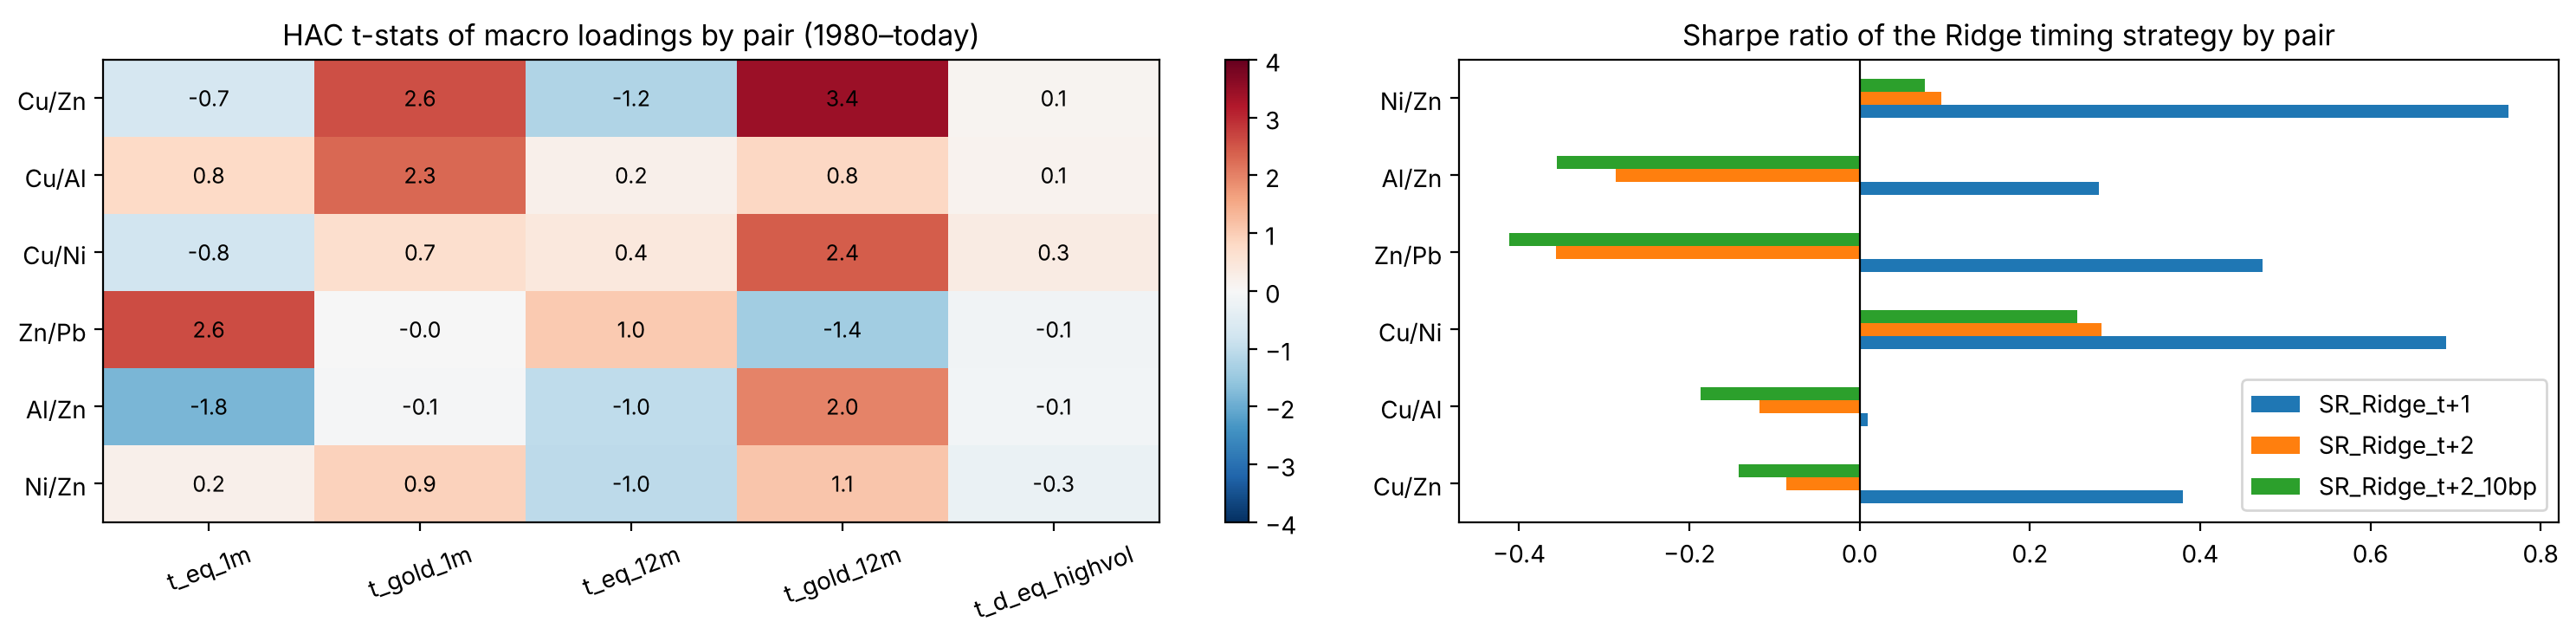

,Cu/Zn,Cu/Al,Cu/Ni,Zn/Pb,Al/Zn,Ni/Zn
Cu/Zn,1.00,0.42,0.37,-0.43,0.55,0.38
Cu/Al,0.42,1.00,0.41,0.02,-0.53,-0.10
Cu/Ni,0.37,0.41,1.00,-0.02,-0.04,-0.72
Zn/Pb,-0.43,0.02,-0.02,1.00,-0.42,-0.30
Al/Zn,0.55,-0.53,-0.04,-0.42,1.00,0.45
Ni/Zn,0.38,-0.10,-0.72,-0.30,0.45,1.00


In [27]:
tcols = ["t_eq_1m", "t_gold_1m", "t_eq_12m", "t_gold_12m", "t_d_eq_highvol"]
T = H5[tcols].astype(float)
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw=dict(width_ratios=[1.2, 1]))
im = ax[0].imshow(T.values, cmap="RdBu_r", vmin=-4, vmax=4, aspect="auto")
ax[0].set_xticks(range(len(tcols)), tcols, rotation=20); ax[0].set_yticks(range(len(T)), T.index)
for i in range(T.shape[0]):
    for j in range(T.shape[1]):
        ax[0].text(j, i, f"{T.iat[i, j]:.1f}", ha="center", va="center", fontsize=9)
ax[0].set_title("HAC t-stats of macro loadings by pair (1980–today)"); fig.colorbar(im, ax=ax[0])
H5[["SR_Ridge_t+1", "SR_Ridge_t+2", "SR_Ridge_t+2_10bp"]].astype(float).plot.barh(ax=ax[1], title="Sharpe ratio of the Ridge timing strategy by pair")
ax[1].axvline(0, c="k", lw=.8)
plt.tight_layout(); plt.show()

# correlation of spread changes across pairs: are these 6 independent tests?
DS = pd.DataFrame({f"{a.capitalize()}/{b.capitalize()}": (lev[a] - lev[b]).diff() for a, b in PAIRS}).loc[S5:]
display(DS.corr().round(2))

**Reading H5 — partly confirmed: Cu/Zn is not special, but neither is the macro story.**

* **Mean reversion depends on the pair and the test.** On 1980–today, Zn/Pb, Al/Zn and Ni/Zn reject a unit root with ADF at 5%, and Cu/Zn only at 10%. Engle–Granger accepts cointegration for Cu/Zn, Zn/Pb and Al/Zn. Johansen finds rank ≥1 for 4 pairs out of 6. KPSS rejects stationarity for every pair except Ni/Zn, and only 9–44% of the 15-year rolling windows look stationary. Half-lives are long (25–40 months; ≈136 for Cu/Al). This is the H1 conclusion for Cu/Zn: mean reversion at best slow and unstable, and the same holds for most pairs. Cu/Al is the least mean-reverting.
* **Macro loadings are small and not systematic.** Only Zn/Pb has a significant 1-month equity beta (+0.15); Cu/Zn and Cu/Al have a significant positive gold beta. No pair has a significant high-vol interaction (|t| < 0.4 everywhere), so H3 fails for **all** pairs.
* **Out-of-sample, the result is identical for all six pairs.** Plain MR beats the historical mean at 1 month (Working effect again). Adding gold and equity information lowers the OOS R² for **6/6** pairs at 1 month. At the skip-month horizon only Cu/Zn gets a Clark–West p below 5% (≈0.02 on this 1980 sample, ≈0.13 on the 1973 sample). With 12 tests (6 pairs × 2 horizons), one such p-value is what chance alone would give: this is the multiple-testing caution of Ch. 7.
* The spread changes of the six pairs are correlated (|ρ| up to 0.7, since they share legs), so these are not 6 independent confirmations. That makes the absence of a common macro effect even more telling.

## 7. Results and comparison with the course

### 7.0 The main evidence in one figure

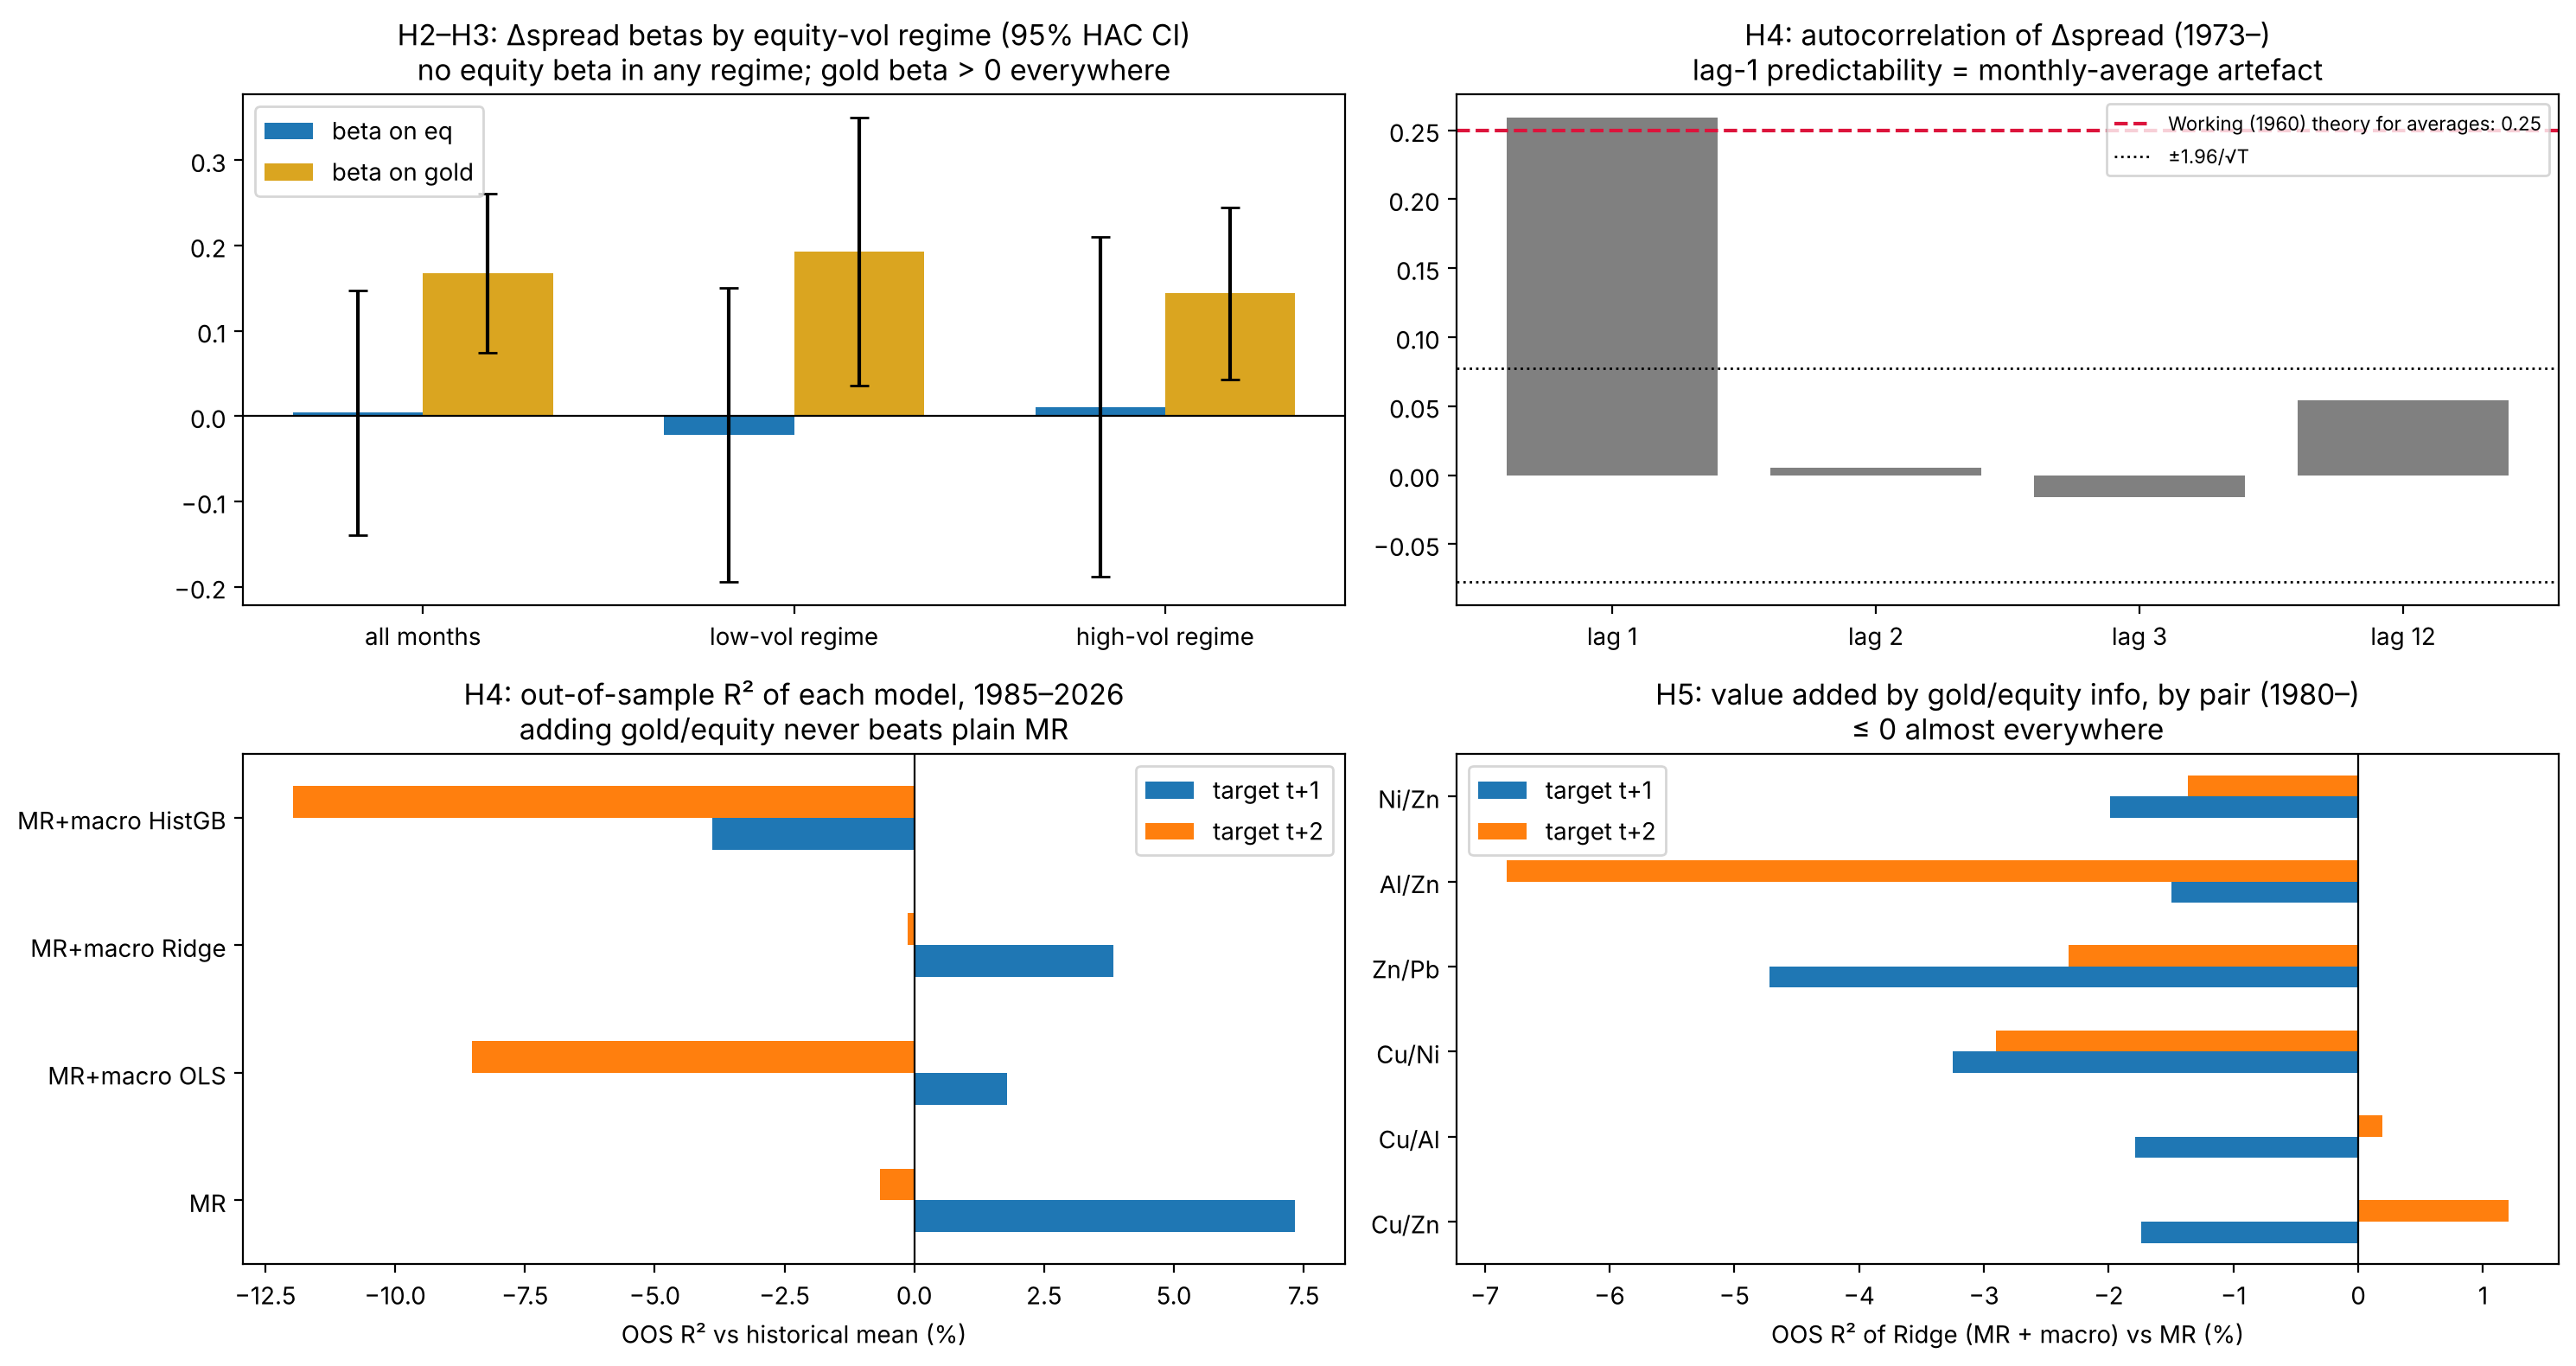

In [28]:
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
# (a) H2/H3: betas by regime with 95% CI
rt = R["H3"]["regime_table"]; xs = np.arange(len(rt)); w = .35
for j, (c, col) in enumerate([("eq", "tab:blue"), ("gold", "goldenrod")]):
    b, t = rt[f"b_{c}"].astype(float), rt[f"t_{c}"].astype(float)
    ax[0, 0].bar(xs + (j - .5) * w, b, w, yerr=1.96 * (b / t).abs(), color=col, capsize=4, label=f"beta on {c}")
ax[0, 0].set_xticks(xs, rt.index); ax[0, 0].axhline(0, c="k", lw=.8); ax[0, 0].legend()
ax[0, 0].set_title("H2–H3: Δspread betas by equity-vol regime (95% HAC CI)\nno equity beta in any regime; gold beta > 0 everywhere")
# (b) Working effect
ac = R["H4_autocorr"]
ax[0, 1].bar(ac.index, ac.values, color="grey"); ax[0, 1].axhline(.25, c="crimson", ls="--", label="Working (1960) theory for averages: 0.25")
ax[0, 1].axhline(1.96 / np.sqrt(len(rets.loc[CFG["start"]:])), c="k", ls=":", lw=1, label="±1.96/√T"); ax[0, 1].axhline(-1.96 / np.sqrt(len(rets.loc[CFG["start"]:])), c="k", ls=":", lw=1)
ax[0, 1].legend(fontsize=8); ax[0, 1].set_title("H4: autocorrelation of Δspread (1973–)\nlag-1 predictability = monthly-average artefact")
# (c) H4: OOS R2 vs historical mean
r2 = pd.DataFrame({f"target t+{l}": R["H4"][l]["R2_oos_vs_HM"] for l in [1, 2]}).drop("HM") * 100
r2.plot.barh(ax=ax[1, 0], color=["tab:blue", "tab:orange"]); ax[1, 0].axvline(0, c="k", lw=.8)
ax[1, 0].set_xlabel("OOS R² vs historical mean (%)"); ax[1, 0].set_title("H4: out-of-sample R² of each model, 1985–2026\nadding gold/equity never beats plain MR")
# (d) H5: macro gain over MR by pair
g = R["H5"][["R2oos_Ridge_vs_MR_t+1", "R2oos_Ridge_vs_MR_t+2"]].astype(float) * 100
g.columns = ["target t+1", "target t+2"]
g.plot.barh(ax=ax[1, 1], color=["tab:blue", "tab:orange"]); ax[1, 1].axvline(0, c="k", lw=.8)
ax[1, 1].set_xlabel("OOS R² of Ridge (MR + macro) vs MR (%)"); ax[1, 1].set_title("H5: value added by gold/equity info, by pair (1980–)\n≤ 0 almost everywhere")
plt.tight_layout(); plt.show()

### 7.1 Key numbers

In [29]:
h3, d1, d2 = R["H3"], R["H4"]["diag"].loc["t+1"], R["H4"]["diag"].loc["t+2"]
t1, t2 = R["H4"][1], R["H4"][2]
summary = pd.DataFrame([
    ["H3", "Equity beta low-vol → high-vol", f"{h3['b_eq_low']:.3f} → {h3['b_eq_high']:.3f}  (t(d_eq) = {h3['t_d_eq']:.2f})"],
    ["H3", "Gold beta low-vol → high-vol", f"{h3['b_gold_low']:.3f} → {h3['b_gold_high']:.3f}  (t(d_gold) = {h3['t_d_gold']:.2f})"],
    ["H3", "Joint Wald p (d_eq = d_gold = 0)", f"{h3['wald_p']:.3f}"],
    ["H3", "Robustness grid: share with t(d_eq) > 1.96", f"{h3['robust_share_pos_sig']:.0%}"],
    ["H3", "corr(P(MS turbulent), equity vol)", f"{h3['ms_corr_vol']:.2f}"],
    ["H4", "OOS R² MR vs HM  (t+1 / t+2)", f"{t1.loc['MR','R2_oos_vs_HM']:.3f} / {t2.loc['MR','R2_oos_vs_HM']:.3f}"],
    ["H4", "OOS R² Ridge vs MR (t+1 / t+2)", f"{t1.loc['MR+macro Ridge','R2_oos_vs_MR']:.3f} / {t2.loc['MR+macro Ridge','R2_oos_vs_MR']:.3f}"],
    ["H4", "Clark–West p Ridge vs MR (t+1 / t+2)", f"{t1.loc['MR+macro Ridge','CW_p_vs_MR']:.3f} / {t2.loc['MR+macro Ridge','CW_p_vs_MR']:.3f}"],
    ["H4", "Ridge strategy SR gross (t+1 / t+2)", f"{d1['SR']:.2f} / {d2['SR']:.2f}"],
    ["H4", "Bootstrap 90% CI of SR (t+2)", f"[{d2['SR_boot_5']:.2f}, {d2['SR_boot_95']:.2f}]"],
    ["H4", "Excess kurtosis / JB of pnl (t+1)", f"{d1['exc_kurt']:.2f} / {d1['JB']:.1f}"],
    ["H5", "Pairs with Johansen rank ≥ 1 (1980–)", f"{int(R['H5']['Johansen_r≥1'].sum())} / {len(R['H5'])}"],
    ["H5", "Pairs with |t_eq_1m| > 1.96", f"{int((R['H5']['t_eq_1m'].astype(float).abs() > 1.96).sum())} / {len(R['H5'])}"],
    ["H5", "Pairs with Ridge OOS R² > 0 vs MR (t+1)", f"{int((R['H5']['R2oos_Ridge_vs_MR_t+1'].astype(float) > 0).sum())} / {len(R['H5'])}"],
], columns=["hypothesis", "statistic", "value"])
display(summary.set_index(["hypothesis", "statistic"]))

value
hypothesis statistic                                                                     
H3         Equity beta low-vol → high-vol                -0.022 → 0.011  (t(d_eq) = 0.26)
           Gold beta low-vol → high-vol                0.193 → 0.144  (t(d_gold) = -0.53)
           Joint Wald p (d_eq = d_gold = 0)                                         0.837
           Robustness grid: share with t(d_eq) > 1.96                                  0%
           corr(P(MS turbulent), equity vol)                                        -0.17
H4         OOS R² MR vs HM  (t+1 / t+2)                                    0.073 / -0.007
           OOS R² Ridge vs MR (t+1 / t+2)                                  -0.038 / 0.005
           Clark–West p Ridge vs MR (t+1 / t+2)                             0.782 / 0.126
           Ridge strategy SR gross (t+1 / t+2)                               0.46 / -0.35
           Bootstrap 90% CI of SR (t+2)                                    [-0.61, -0.12]
           Excess kurtosis / JB of pnl (t+1)                               10.89 / 2490.9
H5         Pairs with Johansen rank ≥ 1 (1980–)                                     4 / 6
           Pairs with |t_eq_1m| > 1.96                                              1 / 6
           Pairs with Ridge OOS R² > 0 vs MR (t+1)                                  0 / 6

### 7.2 Comparison with the course

| course element (chapter) | course result | this project |
|---|---|---|
| Backtest checklist: rationale → predictability → robustness → tradability (Ch. 4) | industry momentum passes all four steps | Cu/Zn fails at step 2: the economic rationale (risk-on copper) is contradicted by H2, and the only predictability is a data artefact (monthly averages) |
| Welch–Goyal: conditional vs unconditional OOS regression (Ch. 20) | macro predictors rarely beat a moving average out-of-sample | same conclusion: gold/equity information never beats plain MR (OOS R² < 0 for 3 learners and 6/6 pairs) |
| Pooling weak signals with Ridge, α sweep, off-the-top (Ch. 20) | Ridge timing pnl positive across α and robust to dropping any feature | here the pnl depends on **one** feature (`Δs_t`): dropping it kills the Sharpe; the α sweep only shrinks towards MR. Pooling does not help when no signal is real |
| Lead-lag Sharpe ratio (Ch. 4) | trending predictors: high lead SR, fast alpha decay; contrarian: negative lead SR | 1-month strategy has the "trending" profile (lead SR ≈2.2 → 0.46 → ≤0), as expected from the positive autocorrelation of average-price changes |
| Tilt / timing decomposition (Ch. 13, 20) | factor timing: mostly timing; S&P timing: both | 1-month: all timing (≈0.53 vs −0.1); skip-month: a losing static tilt |
| Non-normality, JB test, 3-year rolling SR with Lo/Mertens bands (Ch. 11) | momentum pnl: excess kurtosis ≈0.76, JB≈16; SR ≥ ≈1.16 needed for 3-year significance | Δs itself: kurtosis ≈1.4, JB≈63; strategy pnl: kurtosis ≈11. With SR ≈0.46 the 3-year significance threshold is rarely met (≈12% of windows) |
| Style analysis (Ch. 12) | Buffett's alpha becomes insignificant after factor exposures | 1-month pnl: alpha significant (t≈2.6) after eq/gold/Cu/Zn, but it is the averaging artefact; skip-month pnl: mostly a passive short-Cu/long-Zn exposure (R²≈0.48) |
| Turnover, holding period, costs (Ch. 15) | costs reduce momentum Sharpe; slower trading helps | holding period < 1 month ⇒ the Sharpe ratio falls by ≈2/3 at 25 bp per leg |
| Mean reversion / liquidity provision (Ch. 17) | short-horizon cross-sectional reversal of stock returns | for metal ratios, mean reversion of the **level** is slow (half-life 2–4 years) and unstable; at the monthly horizon, average prices show **continuation**, not reversal |

### 7.3 Conclusion
* **H3 rejected:** the (absent) equity sensitivity of the Cu/Zn spread does not become larger in high-vol regimes. The spread's own turbulent regimes, found by Markov switching, are not equity-vol regimes.
* **H4 rejected:** gold and equity information adds no out-of-sample value beyond plain mean reversion. The only robust 1-month predictability comes from averaging (Working 1960) and disappears with a one-month skip.
* **H5:** Cu/Zn is indeed not special: mean reversion is slow and fragile for most LME pairs, macro loadings are small and pair-specific, and no pair shows regime-dependent or out-of-sample macro predictability.
* **Main limitation, and how to go further:** with monthly **average** prices, any trading conclusion is only indicative. The natural next step is to redo §5 with month-end LME cash or 3-month futures prices (e.g. from the LME or a data vendor). This would remove the Working effect at the source and would be the "tradability" test of the course's checklist.